# Fundamentos de Estadística para Machine Learning

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# Estilo de gráficos
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## 1. Medidas de Tendencia Central

¿Cuál es el valor "típico" o "central" de un conjunto de datos?

### 1.1 Media Aritmética (Promedio)

$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$

- **Ventaja**: Usa toda la información disponible
- **Desventaja**: Sensible a valores atípicos (outliers)

### 1.2 Mediana

El valor que divide los datos ordenados en dos mitades iguales.

$$\text{Mediana} = \begin{cases} x_{(n+1)/2} & \text{si } n \text{ es impar} \\ \frac{x_{n/2} + x_{n/2+1}}{2} & \text{si } n \text{ es par} \end{cases}$$

- **Ventaja**: Robusta ante outliers
- **Desventaja**: No usa toda la información

### 1.3 Moda

El valor que más se repite. Puede no existir o haber varias modas.

In [3]:
# =============================================================================
# MEDIDAS DE TENDENCIA CENTRAL — Implementación desde cero
# =============================================================================

def media(datos):
    """Media aritmética."""
    return sum(datos) / len(datos)

def mediana(datos):
    """Mediana."""
    ordenados = sorted(datos)
    n = len(ordenados)
    mid = n // 2
    if n % 2 == 1:
        return ordenados[mid]
    return (ordenados[mid - 1] + ordenados[mid]) / 2

def moda(datos):
    """Moda (valor más frecuente)."""
    conteo = Counter(datos)
    max_freq = max(conteo.values())
    modas = [k for k, v in conteo.items() if v == max_freq]
    return modas

# --- Demostración ---
print("=" * 60)
print("MEDIDAS DE TENDENCIA CENTRAL")
print("=" * 60)

# Dataset normal
datos_normales = [4, 7, 2, 9, 5, 8, 3, 6, 5, 7, 5, 8, 4, 6, 7]
print(f"\nDatos: {sorted(datos_normales)}")
print(f"  Media:   {media(datos_normales):.2f}")
print(f"  Mediana: {mediana(datos_normales):.2f}")
print(f"  Moda:    {moda(datos_normales)}")

# Dataset con outlier
datos_outlier = datos_normales + [100]
print(f"\nDatos con outlier: {sorted(datos_outlier)}")
print(f"  Media:   {media(datos_outlier):.2f}  ← ¡Se dispara por el outlier!")
print(f"  Mediana: {mediana(datos_outlier):.2f}  ← No cambia (robusta)")
print(f"  Moda:    {moda(datos_outlier)}")

# Dataset de salarios (ejemplo realista)
salarios = [2000]*20 + [2500]*15 + [3000]*10 + [4000]*5 + [5000]*3 + [10000]*2 + [50000]*1
print(f"\nSalarios (56 empleados):")
print(f"  Media:   ${media(salarios):,.0f}  ← Inflada por los sueldos altos")
print(f"  Mediana: ${mediana(salarios):,.0f}  ← Más representativa")
print(f"  Moda:    ${moda(salarios)}")
print(f"  → La mediana suele ser mejor para reportar 'el salario típico'")

MEDIDAS DE TENDENCIA CENTRAL

Datos: [2, 3, 4, 4, 5, 5, 5, 6, 6, 7, 7, 7, 8, 8, 9]
  Media:   5.73
  Mediana: 6.00
  Moda:    [7, 5]

Datos con outlier: [2, 3, 4, 4, 5, 5, 5, 6, 6, 7, 7, 7, 8, 8, 9, 100]
  Media:   11.62  ← ¡Se dispara por el outlier!
  Mediana: 6.00  ← No cambia (robusta)
  Moda:    [7, 5]

Salarios (56 empleados):
  Media:   $3,795  ← Inflada por los sueldos altos
  Mediana: $2,500  ← Más representativa
  Moda:    $[2000]
  → La mediana suele ser mejor para reportar 'el salario típico'


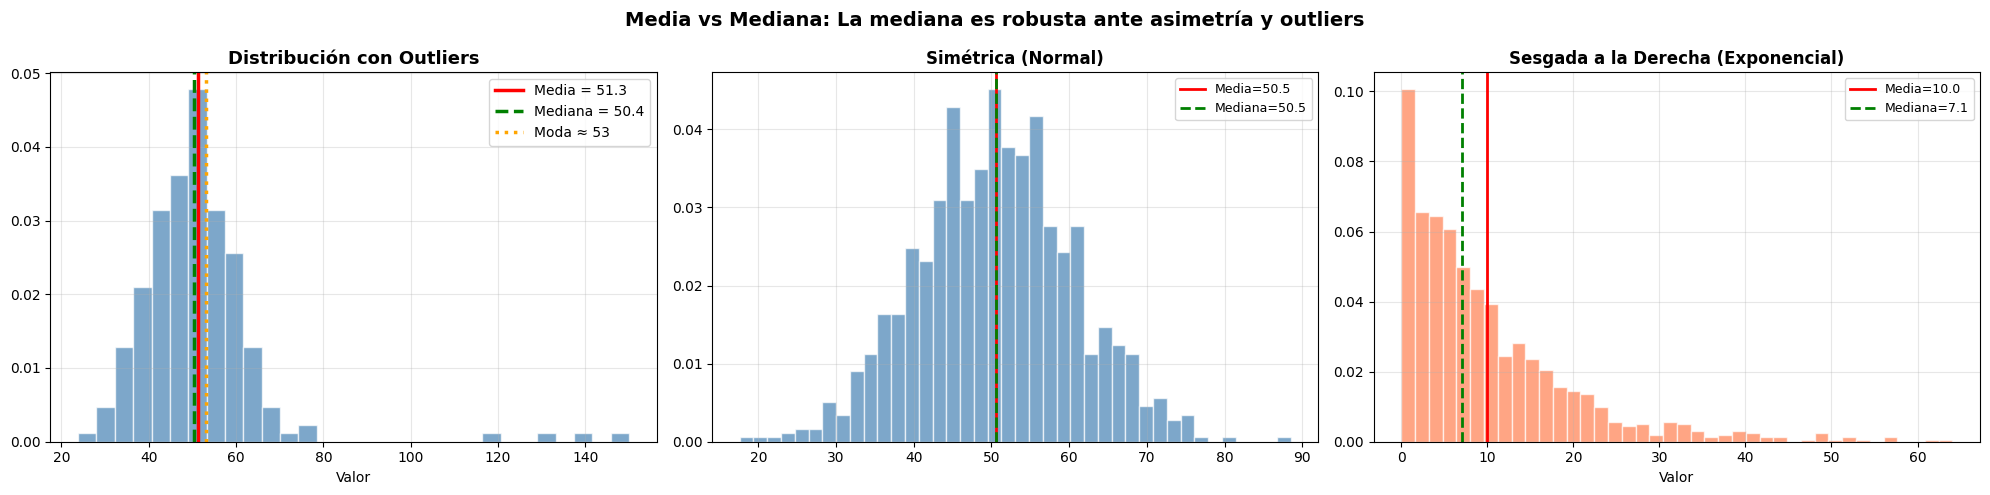

💡 En distribuciones simétricas: Media ≈ Mediana
   En distribuciones sesgadas: Media se desplaza hacia la cola


In [4]:
# --- Visualización de tendencia central ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Comparación visual: media vs mediana
datos = np.concatenate([np.random.normal(50, 10, 200), [120, 130, 140, 150]])  # Con outliers

axes[0].hist(datos, bins=30, color='steelblue', alpha=0.7, edgecolor='white', density=True)
axes[0].axvline(np.mean(datos), color='red', linewidth=2.5, linestyle='-', label=f'Media = {np.mean(datos):.1f}')
axes[0].axvline(np.median(datos), color='green', linewidth=2.5, linestyle='--', label=f'Mediana = {np.median(datos):.1f}')
m = stats.mode(np.round(datos, 0), keepdims=True).mode[0]
axes[0].axvline(m, color='orange', linewidth=2.5, linestyle=':', label=f'Moda ≈ {m:.0f}')
axes[0].set_title('Distribución con Outliers', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].set_xlabel('Valor')

# 2. Tres tipos de distribución
for ax, data, title, color in [
    (axes[1], np.random.normal(50, 10, 1000), 'Simétrica (Normal)', 'steelblue'),
]:
    ax.hist(data, bins=40, color=color, alpha=0.7, density=True, edgecolor='white')
    ax.axvline(np.mean(data), color='red', linewidth=2, label=f'Media={np.mean(data):.1f}')
    ax.axvline(np.median(data), color='green', linewidth=2, linestyle='--', label=f'Mediana={np.median(data):.1f}')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)

# Sesgada a la derecha
data_skew = np.random.exponential(10, 1000)
axes[2].hist(data_skew, bins=40, color='coral', alpha=0.7, density=True, edgecolor='white')
axes[2].axvline(np.mean(data_skew), color='red', linewidth=2, label=f'Media={np.mean(data_skew):.1f}')
axes[2].axvline(np.median(data_skew), color='green', linewidth=2, linestyle='--', label=f'Mediana={np.median(data_skew):.1f}')
axes[2].set_title('Sesgada a la Derecha (Exponencial)', fontweight='bold')
axes[2].legend(fontsize=9)
axes[2].set_xlabel('Valor')

plt.suptitle('Media vs Mediana: La mediana es robusta ante asimetría y outliers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 En distribuciones simétricas: Media ≈ Mediana")
print("   En distribuciones sesgadas: Media se desplaza hacia la cola")

## 2. Medidas de Dispersión

¿Qué tan "esparcidos" están los datos alrededor del centro?

### 2.1 Rango
$$\text{Rango} = x_{\max} - x_{\min}$$

### 2.2 Varianza
$$\sigma^2 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^2 \quad \text{(poblacional)}$$
$$s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2 \quad \text{(muestral, corrección de Bessel)}$$

### 2.3 Desviación Estándar
$$\sigma = \sqrt{\sigma^2}$$

Tiene las **mismas unidades** que los datos (a diferencia de la varianza).

### 2.4 Rango Intercuartílico (IQR)
$$IQR = Q_3 - Q_1$$

Donde $Q_1$ es el percentil 25 y $Q_3$ el percentil 75. Robusto ante outliers.

### 2.5 Coeficiente de Variación (CV)
$$CV = \frac{\sigma}{\bar{x}} \times 100\%$$

Permite comparar dispersión entre variables con diferentes escalas.

In [5]:
# =============================================================================
# MEDIDAS DE DISPERSIÓN — Implementación desde cero
# =============================================================================

def rango(datos):
    return max(datos) - min(datos)

def varianza(datos, muestral=True):
    """Varianza. muestral=True usa n-1 (corrección de Bessel)."""
    n = len(datos)
    m = media(datos)
    ss = sum((x - m)**2 for x in datos)
    return ss / (n - 1) if muestral else ss / n

def desviacion_estandar(datos, muestral=True):
    return varianza(datos, muestral) ** 0.5

def percentil(datos, p):
    """Percentil p (0-100)."""
    ordenados = sorted(datos)
    k = (len(ordenados) - 1) * p / 100
    f = int(k)
    c = k - f
    if f + 1 < len(ordenados):
        return ordenados[f] + c * (ordenados[f+1] - ordenados[f])
    return ordenados[f]

def iqr(datos):
    return percentil(datos, 75) - percentil(datos, 25)

def coeficiente_variacion(datos):
    return (desviacion_estandar(datos) / media(datos)) * 100

# --- Demostración ---
print("=" * 60)
print("MEDIDAS DE DISPERSIÓN")
print("=" * 60)

# Tres datasets con misma media pero diferente dispersión
np.random.seed(42)
d_baja = np.random.normal(50, 5, 200)    # σ = 5
d_media = np.random.normal(50, 15, 200)   # σ = 15
d_alta = np.random.normal(50, 30, 200)    # σ = 30

for nombre, datos in [("Baja dispersión", d_baja), ("Media dispersión", d_media), ("Alta dispersión", d_alta)]:
    print(f"\n{nombre}:")
    print(f"  Media:    {media(datos):.2f}")
    print(f"  Rango:    {rango(datos):.2f}")
    print(f"  Varianza: {varianza(datos):.2f}")
    print(f"  Desv. Est: {desviacion_estandar(datos):.2f}")
    print(f"  IQR:      {iqr(datos):.2f}")
    print(f"  CV:       {coeficiente_variacion(datos):.1f}%")

# Verificar con numpy
print(f"\n✅ Verificación (alta dispersión):")
print(f"  np.std(ddof=1): {np.std(d_alta, ddof=1):.2f} vs nuestra: {desviacion_estandar(d_alta):.2f}")

MEDIDAS DE DISPERSIÓN

Baja dispersión:
  Media:    49.80
  Rango:    26.70
  Varianza: 21.67
  Desv. Est: 4.66
  IQR:      6.03
  CV:       9.3%

Media dispersión:
  Media:    51.29
  Rango:    106.41
  Varianza: 219.19
  Desv. Est: 14.81
  IQR:      19.40
  CV:       28.9%

Alta dispersión:
  Media:    47.43
  Rango:    166.52
  Varianza: 889.31
  Desv. Est: 29.82
  IQR:      40.98
  CV:       62.9%

✅ Verificación (alta dispersión):
  np.std(ddof=1): 29.82 vs nuestra: 29.82


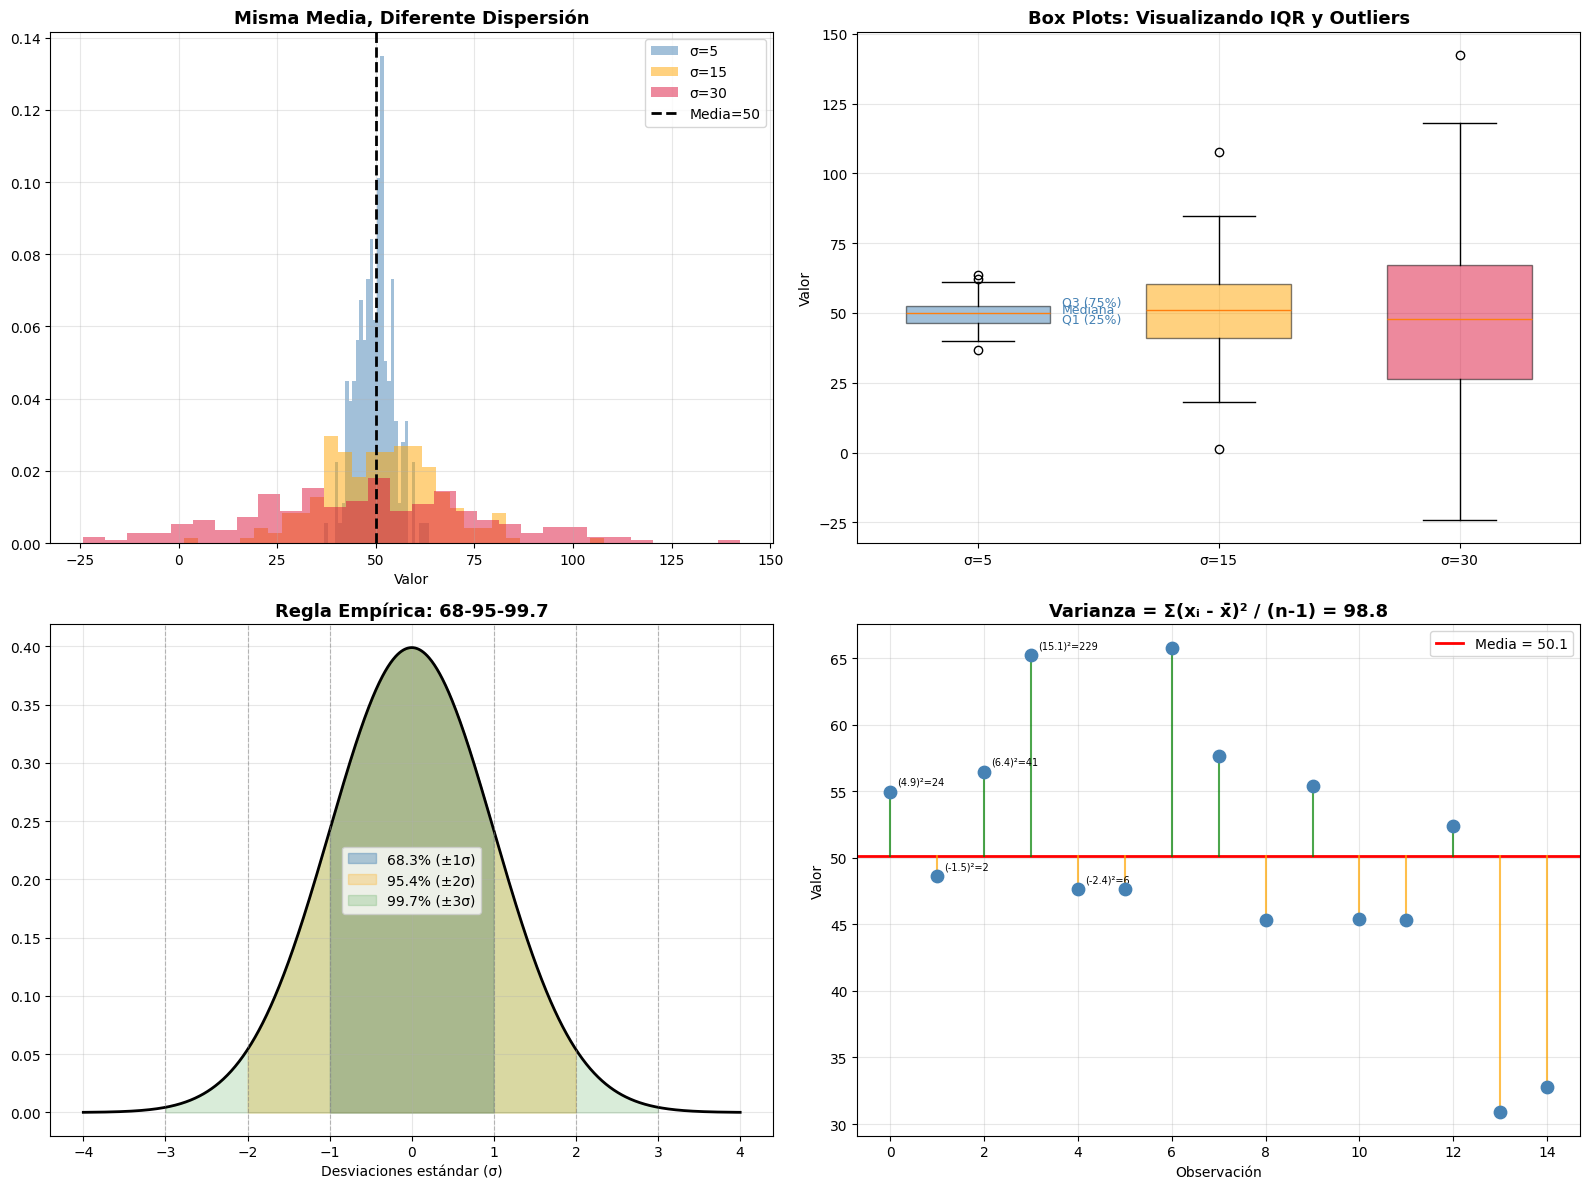

In [6]:
# --- Visualización de dispersión ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Tres distribuciones con misma media, diferente σ
for datos, label, color in [(d_baja, 'σ=5', 'steelblue'),
                             (d_media, 'σ=15', 'orange'),
                             (d_alta, 'σ=30', 'crimson')]:
    axes[0,0].hist(datos, bins=30, alpha=0.5, label=label, color=color, density=True)
axes[0,0].axvline(50, color='black', linewidth=2, linestyle='--', label='Media=50')
axes[0,0].set_title('Misma Media, Diferente Dispersión', fontsize=13, fontweight='bold')
axes[0,0].legend()
axes[0,0].set_xlabel('Valor')

# 2. Box plots comparativos
bp = axes[0,1].boxplot([d_baja, d_media, d_alta], labels=['σ=5', 'σ=15', 'σ=30'],
                       patch_artist=True, widths=0.6)
colors_bp = ['steelblue', 'orange', 'crimson']
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
axes[0,1].set_title('Box Plots: Visualizando IQR y Outliers', fontsize=13, fontweight='bold')
axes[0,1].set_ylabel('Valor')

# Anotar partes del boxplot
axes[0,1].annotate('Q3 (75%)', xy=(1.35, np.percentile(d_baja, 75)), fontsize=9, color='steelblue')
axes[0,1].annotate('Mediana', xy=(1.35, np.median(d_baja)), fontsize=9, color='steelblue')
axes[0,1].annotate('Q1 (25%)', xy=(1.35, np.percentile(d_baja, 25)), fontsize=9, color='steelblue')

# 3. Regla empírica (68-95-99.7)
data_normal = np.random.normal(0, 1, 10000)
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x, 0, 1)

axes[1,0].plot(x, y, 'k-', linewidth=2)
axes[1,0].fill_between(x, y, where=(x >= -1) & (x <= 1), alpha=0.4, color='steelblue', label='68.3% (±1σ)')
axes[1,0].fill_between(x, y, where=(x >= -2) & (x <= 2), alpha=0.25, color='orange', label='95.4% (±2σ)')
axes[1,0].fill_between(x, y, where=(x >= -3) & (x <= 3), alpha=0.15, color='green', label='99.7% (±3σ)')

for s, pct in [(-1, ''), (1, '68.3%'), (-2, ''), (2, '95.4%'), (-3, ''), (3, '99.7%')]:
    axes[1,0].axvline(s, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

axes[1,0].set_title('Regla Empírica: 68-95-99.7', fontsize=13, fontweight='bold')
axes[1,0].set_xlabel('Desviaciones estándar (σ)')
axes[1,0].legend(fontsize=10)

# 4. Varianza: desviaciones al cuadrado
np.random.seed(42)
sample = np.random.normal(50, 10, 15)
m = np.mean(sample)

axes[1,1].scatter(range(len(sample)), sample, c='steelblue', s=80, zorder=5)
axes[1,1].axhline(m, color='red', linewidth=2, label=f'Media = {m:.1f}')

for i, x in enumerate(sample):
    color = 'green' if x > m else 'orange'
    axes[1,1].plot([i, i], [m, x], color=color, linewidth=1.5, alpha=0.7)
    dev = (x - m)**2
    if i < 5:  # Anotar solo algunos para claridad
        axes[1,1].annotate(f'({x-m:.1f})²={dev:.0f}', (i, x),
                          textcoords="offset points", xytext=(5, 5), fontsize=7)

axes[1,1].set_title(f'Varianza = Σ(xᵢ - x̄)² / (n-1) = {np.var(sample, ddof=1):.1f}',
                    fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('Observación')
axes[1,1].set_ylabel('Valor')
axes[1,1].legend()

plt.tight_layout()
plt.show()

## 3. Momentos Estadísticos: Asimetría y Curtosis

Los momentos describen la **forma** de una distribución.

### 3.1 Momentos Centrales

El momento central de orden $k$:

$$\mu_k = \frac{1}{n} \sum_{i=1}^{n} (x_i - \bar{x})^k$$

| Momento | $k$ | ¿Qué mide? |
|---------|-----|-----------|
| Media | 1 | Centro |
| Varianza | 2 | Dispersión |
| **Asimetría (Skewness)** | 3 | ¿Cola izquierda o derecha? |
| **Curtosis (Kurtosis)** | 4 | ¿Colas pesadas o ligeras? |

### 3.2 Asimetría (Skewness)

$$\gamma_1 = \frac{\mu_3}{\sigma^3} = \frac{\frac{1}{n}\sum(x_i - \bar{x})^3}{\left(\frac{1}{n}\sum(x_i - \bar{x})^2\right)^{3/2}}$$

- $\gamma_1 < 0$: Cola hacia la **izquierda** (sesgo negativo)
- $\gamma_1 = 0$: **Simétrica**
- $\gamma_1 > 0$: Cola hacia la **derecha** (sesgo positivo)

### 3.3 Curtosis (Kurtosis)

$$\gamma_2 = \frac{\mu_4}{\sigma^4} - 3$$

(Se resta 3 para que la normal tenga curtosis 0 — "exceso de curtosis")

- $\gamma_2 < 0$: **Platicúrtica** (colas ligeras, más plana que la normal)
- $\gamma_2 = 0$: **Mesocúrtica** (como la normal)
- $\gamma_2 > 0$: **Leptocúrtica** (colas pesadas, más puntiaguda)

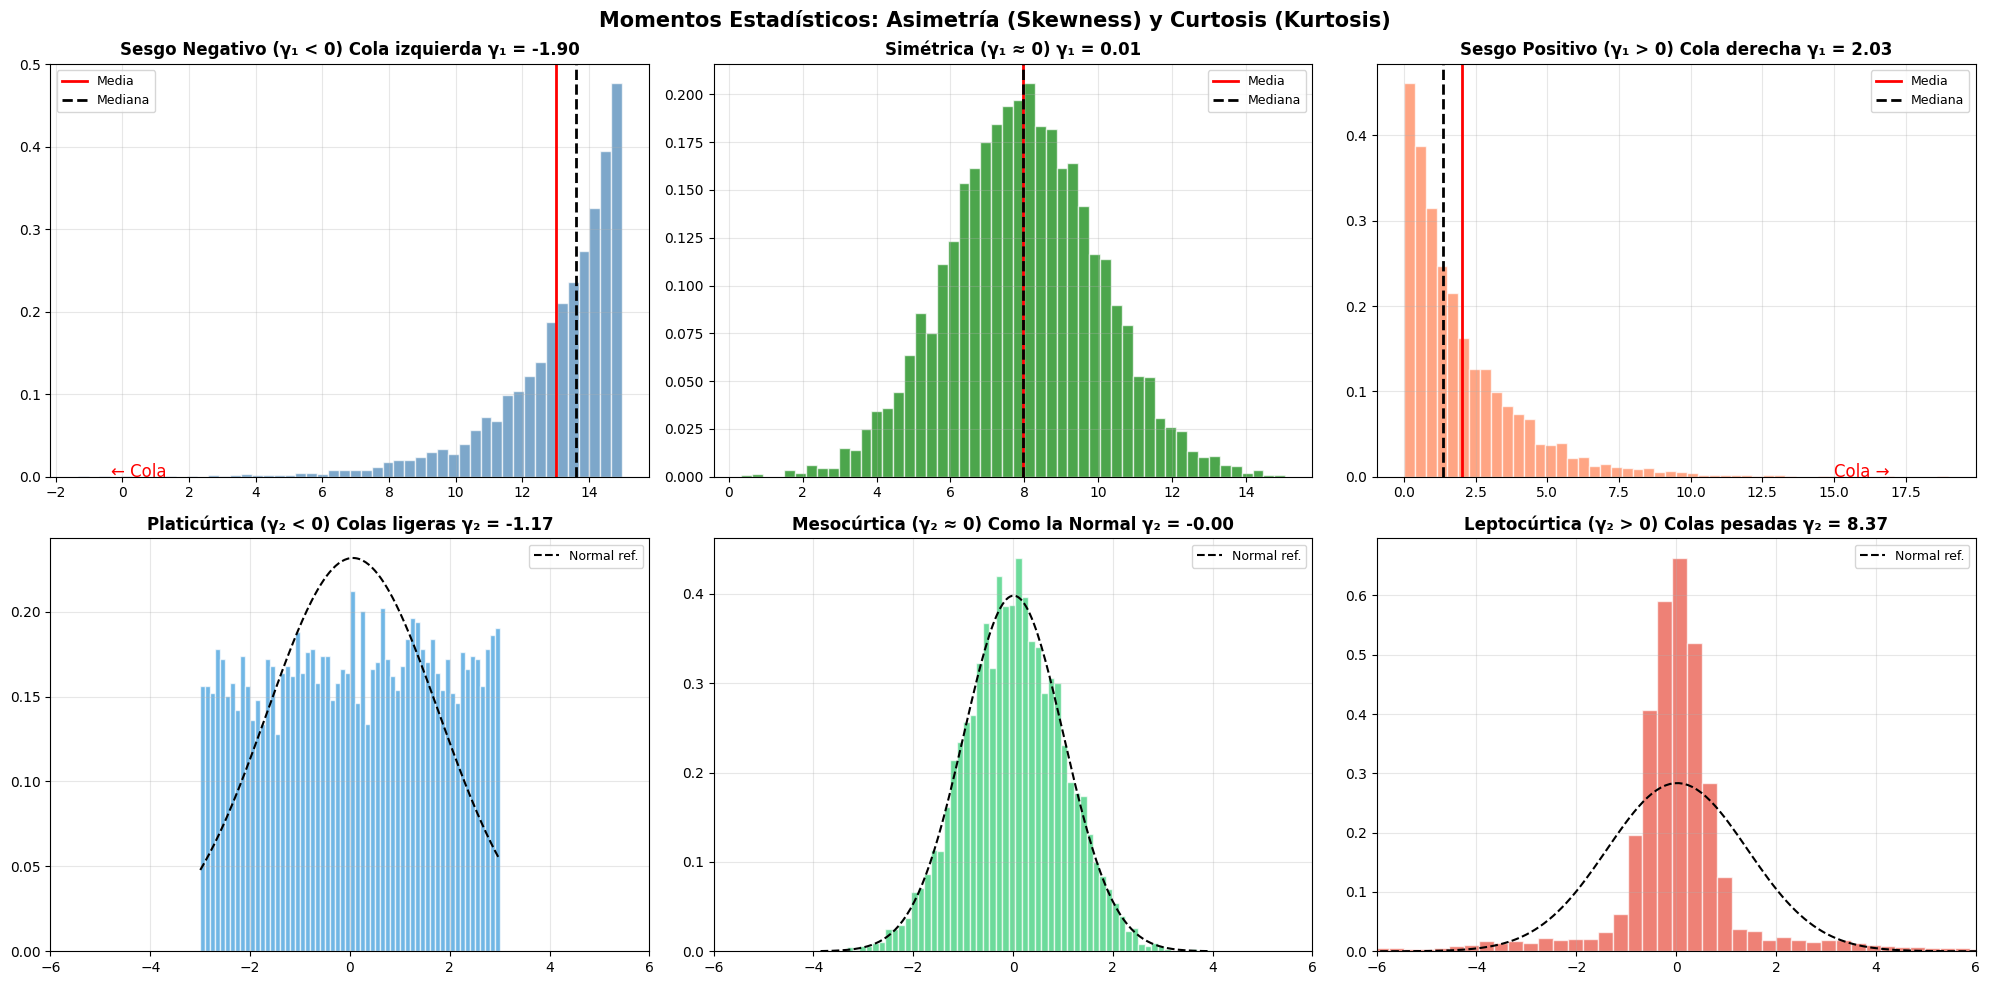

✅ Verificación con scipy.stats:
    Neg Skew: Skew=-1.904 (scipy: -1.904), Kurt=+4.978 (scipy: +4.978)
   Simétrica: Skew=+0.006 (scipy: +0.006), Kurt=+0.062 (scipy: +0.062)
    Pos Skew: Skew=+2.032 (scipy: +2.032), Kurt=+5.937 (scipy: +5.937)


In [7]:
# =============================================================================
# MOMENTOS ESTADÍSTICOS
# =============================================================================

def momento_central(datos, k):
    """Momento central de orden k."""
    m = media(datos)
    return sum((x - m)**k for x in datos) / len(datos)

def asimetria(datos):
    """Skewness (asimetría)."""
    return momento_central(datos, 3) / momento_central(datos, 2)**1.5

def curtosis(datos):
    """Exceso de curtosis (kurtosis - 3)."""
    return momento_central(datos, 4) / momento_central(datos, 2)**2 - 3

# --- Demostración visual ---
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# Asimetría
np.random.seed(42)
data_neg_skew = -np.random.exponential(2, 5000) + 15
data_sym = np.random.normal(8, 2, 5000)
data_pos_skew = np.random.exponential(2, 5000)

skew_data = [(data_neg_skew, 'Sesgo Negativo (γ₁ < 0) Cola izquierda', 'steelblue'),
             (data_sym, 'Simétrica (γ₁ ≈ 0)', 'green'),
             (data_pos_skew, 'Sesgo Positivo (γ₁ > 0) Cola derecha', 'coral')]

for i, (data, title, color) in enumerate(skew_data):
    sk = asimetria(data)
    axes[0, i].hist(data, bins=50, color=color, alpha=0.7, density=True, edgecolor='white')
    axes[0, i].axvline(np.mean(data), color='red', linewidth=2, linestyle='-', label=f'Media')
    axes[0, i].axvline(np.median(data), color='black', linewidth=2, linestyle='--', label=f'Mediana')
    axes[0, i].set_title(f'{title} γ₁ = {sk:.2f}', fontsize=12, fontweight='bold')
    axes[0, i].legend(fontsize=9)
    if sk < 0:
        axes[0, i].annotate('← Cola', xy=(data.min() + 1, 0), fontsize=12, color='red')
    elif sk > 0.5:
        axes[0, i].annotate('Cola →', xy=(data.max() - 4, 0), fontsize=12, color='red')

# Curtosis
data_platy = np.random.uniform(-3, 3, 5000)  # Platicúrtica
data_meso = np.random.normal(0, 1, 5000)      # Mesocúrtica
data_lepto = np.concatenate([np.random.normal(0, 0.5, 4000),
                              np.random.normal(0, 3, 1000)])  # Leptocúrtica

kurt_data = [(data_platy, 'Platicúrtica (γ₂ < 0) Colas ligeras', '#3498DB'),
             (data_meso, 'Mesocúrtica (γ₂ ≈ 0) Como la Normal', '#2ECC71'),
             (data_lepto, 'Leptocúrtica (γ₂ > 0) Colas pesadas', '#E74C3C')]

for i, (data, title, color) in enumerate(kurt_data):
    kt = curtosis(data)
    axes[1, i].hist(data, bins=60, color=color, alpha=0.7, density=True, edgecolor='white')
    # Superponer normal
    x = np.linspace(data.min(), data.max(), 200)
    axes[1, i].plot(x, stats.norm.pdf(x, np.mean(data), np.std(data)),
                   'k--', linewidth=1.5, label='Normal ref.')
    axes[1, i].set_title(f'{title} γ₂ = {kt:.2f}', fontsize=12, fontweight='bold')
    axes[1, i].legend(fontsize=9)
    axes[1, i].set_xlim(-6, 6)

plt.suptitle('Momentos Estadísticos: Asimetría (Skewness) y Curtosis (Kurtosis)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# Verificación
print("✅ Verificación con scipy.stats:")
for name, data in [("Neg Skew", data_neg_skew), ("Simétrica", data_sym), ("Pos Skew", data_pos_skew)]:
    print(f"  {name:>10}: Skew={asimetria(data):+.3f} (scipy: {stats.skew(data):+.3f}), "
          f"Kurt={curtosis(data):+.3f} (scipy: {stats.kurtosis(data):+.3f})")

## 4. Distribuciones de Probabilidad

Las distribuciones describen **cómo se distribuyen** los valores posibles de una variable.

### Distribuciones Discretas
| Distribución | Parámetros | Ejemplo |
|---|---|---|
| **Bernoulli** | $p$ | Lanzar una moneda |
| **Binomial** | $n, p$ | # éxitos en n intentos |
| **Poisson** | $\lambda$ | # eventos por unidad de tiempo |

### Distribuciones Continuas
| Distribución | Parámetros | Ejemplo |
|---|---|---|
| **Uniforme** | $a, b$ | Número aleatorio en [a,b] |
| **Normal** | $\mu, \sigma$ | Alturas, errores, todo en ML |
| **Exponencial** | $\lambda$ | Tiempo entre eventos |
| **t-Student** | $\nu$ (grados de libertad) | Muestras pequeñas |
| **Chi-cuadrado** | $k$ | Pruebas de bondad de ajuste |

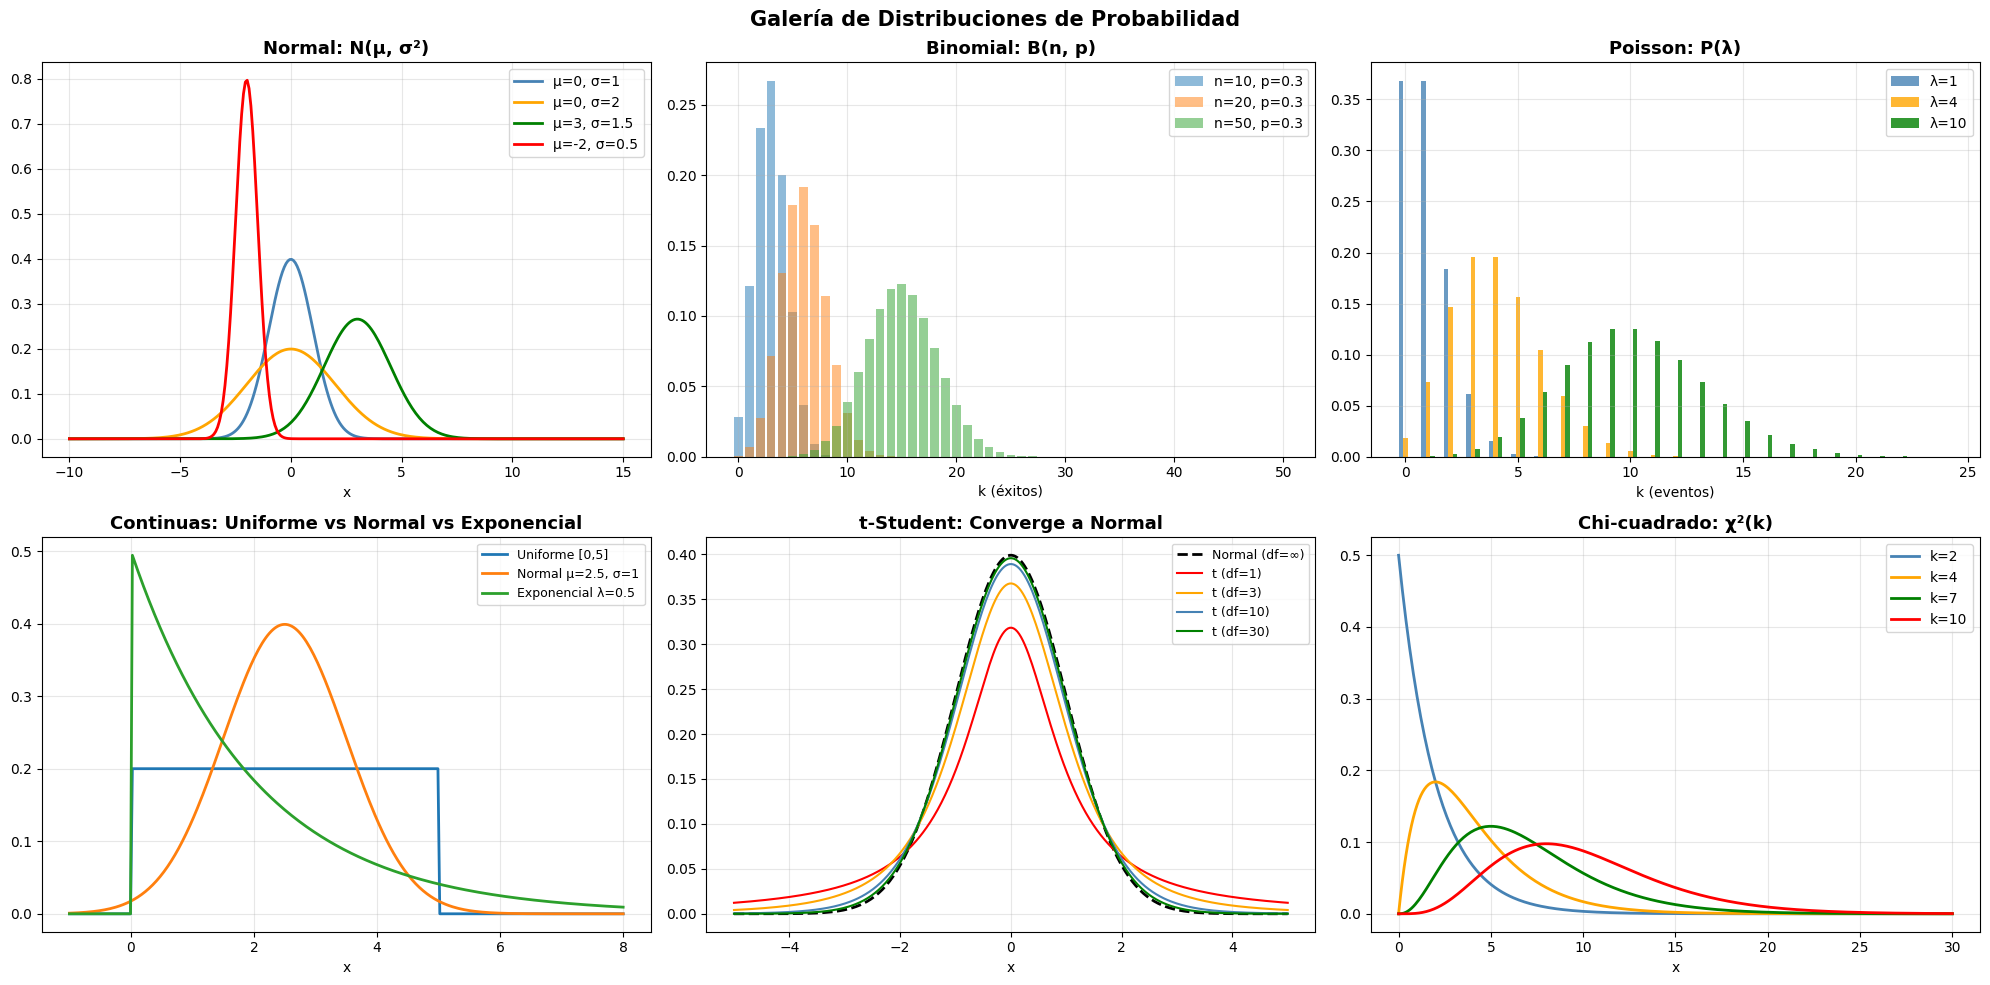

In [8]:
# --- Galería de distribuciones ---
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# 1. Normal con diferentes parámetros
x = np.linspace(-10, 15, 300)
for mu, sigma, c in [(0, 1, 'steelblue'), (0, 2, 'orange'), (3, 1.5, 'green'), (-2, 0.5, 'red')]:
    axes[0,0].plot(x, stats.norm.pdf(x, mu, sigma), linewidth=2,
                  label=f'μ={mu}, σ={sigma}', color=c)
axes[0,0].set_title('Normal: N(μ, σ²)', fontsize=13, fontweight='bold')
axes[0,0].legend(); axes[0,0].set_xlabel('x')

# 2. Binomial
n_vals = [10, 20, 50]
p = 0.3
for n in n_vals:
    k = np.arange(0, n+1)
    axes[0,1].bar(k, stats.binom.pmf(k, n, p), alpha=0.5, label=f'n={n}, p={p}')
axes[0,1].set_title('Binomial: B(n, p)', fontsize=13, fontweight='bold')
axes[0,1].legend(); axes[0,1].set_xlabel('k (éxitos)')

# 3. Poisson
for lam, c in [(1, 'steelblue'), (4, 'orange'), (10, 'green')]:
    k = np.arange(0, 25)
    axes[0,2].bar(k + {'steelblue': -0.2, 'orange': 0, 'green': 0.2}[c],
                 stats.poisson.pmf(k, lam), width=0.2, color=c, alpha=0.8, label=f'λ={lam}')
axes[0,2].set_title('Poisson: P(λ)', fontsize=13, fontweight='bold')
axes[0,2].legend(); axes[0,2].set_xlabel('k (eventos)')

# 4. Uniforme vs Normal vs Exponencial
x = np.linspace(-1, 8, 300)
axes[1,0].plot(x, stats.uniform.pdf(x, 0, 5), linewidth=2, label='Uniforme [0,5]')
axes[1,0].plot(x, stats.norm.pdf(x, 2.5, 1), linewidth=2, label='Normal μ=2.5, σ=1')
axes[1,0].plot(x, stats.expon.pdf(x, scale=2), linewidth=2, label='Exponencial λ=0.5')
axes[1,0].set_title('Continuas: Uniforme vs Normal vs Exponencial', fontsize=13, fontweight='bold')
axes[1,0].legend(fontsize=9); axes[1,0].set_xlabel('x')

# 5. t-Student (converge a Normal)
x = np.linspace(-5, 5, 300)
axes[1,1].plot(x, stats.norm.pdf(x), 'k--', linewidth=2, label='Normal (df=∞)')
for df, c in [(1, 'red'), (3, 'orange'), (10, 'steelblue'), (30, 'green')]:
    axes[1,1].plot(x, stats.t.pdf(x, df), linewidth=1.5, label=f't (df={df})', color=c)
axes[1,1].set_title('t-Student: Converge a Normal', fontsize=13, fontweight='bold')
axes[1,1].legend(fontsize=9); axes[1,1].set_xlabel('x')

# 6. Chi-cuadrado
x = np.linspace(0, 30, 300)
for k, c in [(2, 'steelblue'), (4, 'orange'), (7, 'green'), (10, 'red')]:
    axes[1,2].plot(x, stats.chi2.pdf(x, k), linewidth=2, label=f'k={k}', color=c)
axes[1,2].set_title('Chi-cuadrado: χ²(k)', fontsize=13, fontweight='bold')
axes[1,2].legend(); axes[1,2].set_xlabel('x')

plt.suptitle('Galería de Distribuciones de Probabilidad', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Covarianza y Correlación

### 5.1 Covarianza

Mide cómo varían **juntas** dos variables:

$$\text{Cov}(X, Y) = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$

- $\text{Cov} > 0$: Cuando X sube, Y tiende a subir
- $\text{Cov} < 0$: Cuando X sube, Y tiende a bajar
- $\text{Cov} ≈ 0$: No hay relación lineal

**Problema**: La covarianza depende de las **unidades** de las variables.

### 5.2 Correlación de Pearson

Normaliza la covarianza para obtener un valor entre -1 y 1:

$$r = \frac{\text{Cov}(X, Y)}{\sigma_X \cdot \sigma_Y}, \quad r \in [-1, 1]$$

| $r$ | Interpretación |
|-----|---------------|
| 1 | Correlación positiva perfecta |
| 0.7 a 1 | Correlación positiva fuerte |
| 0.3 a 0.7 | Correlación positiva moderada |
| 0 | Sin correlación lineal |
| -1 | Correlación negativa perfecta |

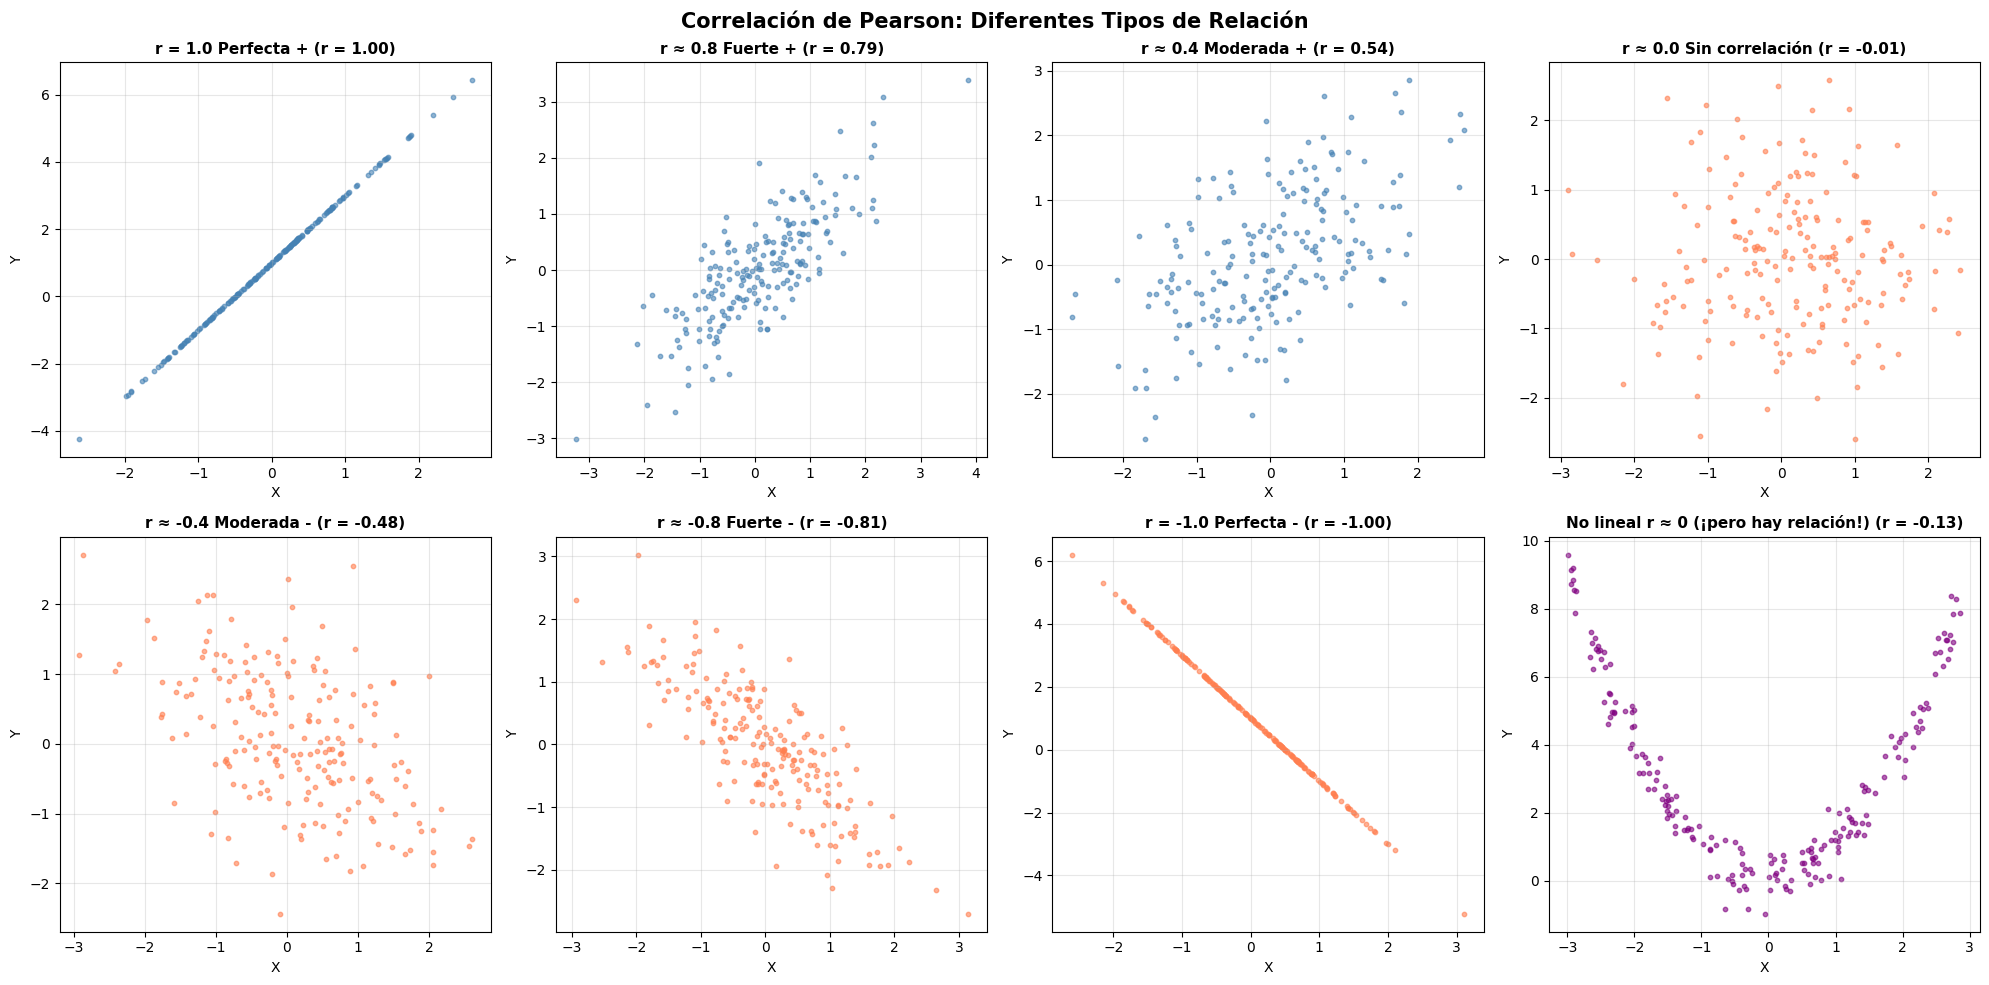

⚠️ IMPORTANTE: Correlación ≠ Causalidad
   - r ≈ 0 no significa 'sin relación' (puede ser no lineal)
   - r fuerte no implica que X cause Y


In [9]:
# =============================================================================
# COVARIANZA Y CORRELACIÓN
# =============================================================================

def covarianza(x, y):
    mx, my = media(x), media(y)
    return sum((xi - mx) * (yi - my) for xi, yi in zip(x, y)) / (len(x) - 1)

def correlacion_pearson(x, y):
    return covarianza(x, y) / (desviacion_estandar(x) * desviacion_estandar(y))

# --- Visualización de diferentes correlaciones ---
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

np.random.seed(42)
n = 200

correlaciones = [
    (1.0, 'r = 1.0 Perfecta +'), (0.8, 'r ≈ 0.8 Fuerte +'),
    (0.4, 'r ≈ 0.4 Moderada +'), (0.0, 'r ≈ 0.0 Sin correlación'),
    (-0.4, 'r ≈ -0.4 Moderada -'), (-0.8, 'r ≈ -0.8 Fuerte -'),
    (-1.0, 'r = -1.0 Perfecta -'), (None, 'No lineal r ≈ 0 (¡pero hay relación!)')
]

for idx, (r_target, title) in enumerate(correlaciones):
    row, col = idx // 4, idx % 4

    if r_target is not None and abs(r_target) < 1:
        # Generar datos con correlación específica
        x = np.random.normal(0, 1, n)
        noise = np.random.normal(0, 1, n)
        y = r_target * x + np.sqrt(1 - r_target**2) * noise
    elif r_target == 1.0:
        x = np.random.normal(0, 1, n)
        y = 2 * x + 1
    elif r_target == -1.0:
        x = np.random.normal(0, 1, n)
        y = -2 * x + 1
    else:
        # Relación no lineal (cuadrática)
        x = np.random.uniform(-3, 3, n)
        y = x**2 + np.random.normal(0, 0.5, n)

    r_real = np.corrcoef(x, y)[0, 1]
    color = 'steelblue' if r_real >= 0 else 'coral'
    if r_target is None: color = 'purple'

    axes[row, col].scatter(x, y, s=10, alpha=0.6, color=color)
    axes[row, col].set_title(f'{title} (r = {r_real:.2f})', fontsize=11, fontweight='bold')
    axes[row, col].set_xlabel('X'); axes[row, col].set_ylabel('Y')

plt.suptitle('Correlación de Pearson: Diferentes Tipos de Relación', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("⚠️ IMPORTANTE: Correlación ≠ Causalidad")
print("   - r ≈ 0 no significa 'sin relación' (puede ser no lineal)")
print("   - r fuerte no implica que X cause Y")

## 6. Ley de los Grandes Números (LGN)

### Enunciado

A medida que el número de observaciones $n$ crece, el promedio muestral
**converge** al valor esperado (media poblacional):

$$\bar{X}_n = \frac{1}{n}\sum_{i=1}^{n} X_i \xrightarrow{n \to \infty} \mu = E[X]$$

### Intuición

Si lanzas una moneda justa:
- 10 lanzamientos: podrías obtener 70% caras (lejos de 50%)
- 100 lanzamientos: probablemente 45-55% caras
- 10,000 lanzamientos: casi seguro 49.5-50.5% caras

### Importancia en ML

- Justifica el uso de **promedios muestrales** como estimadores
- Las **métricas de evaluación** (accuracy, loss) convergen con más datos
- El **SGD** funciona porque el gradiente promedio converge al gradiente real

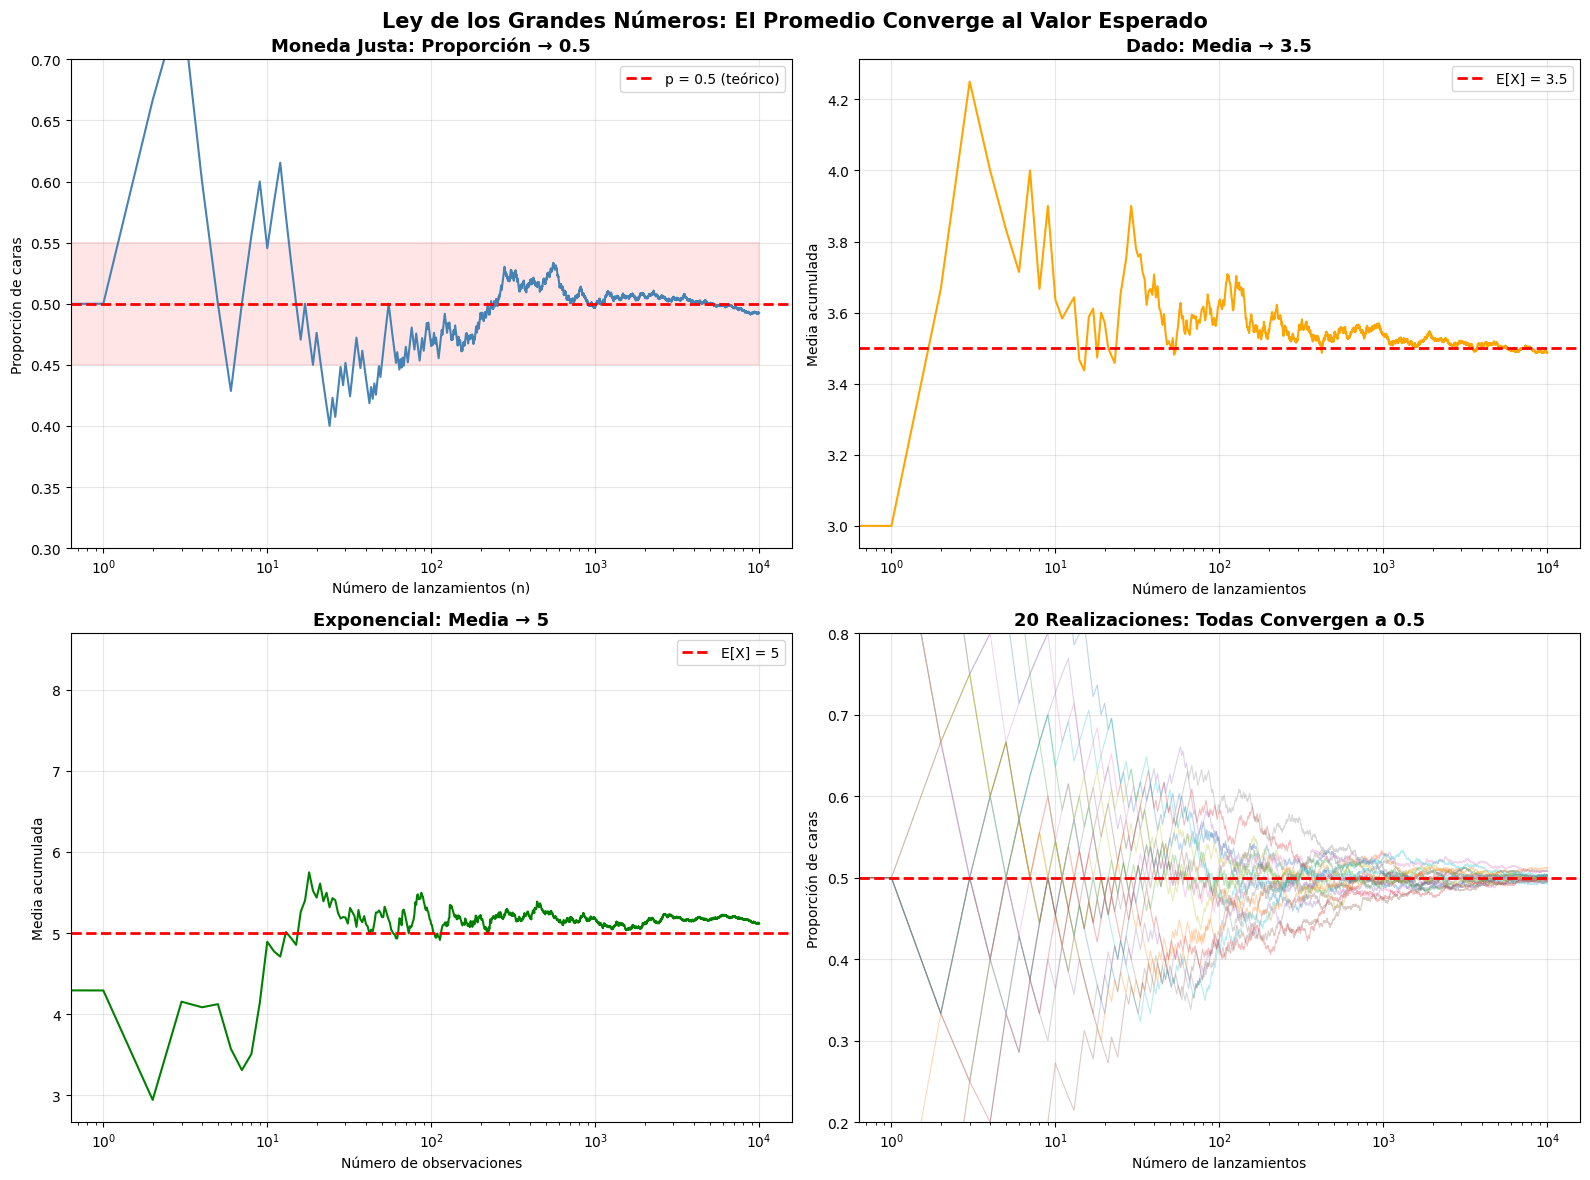

💡 La LGN nos dice: con suficientes datos, el promedio muestral
   es una estimación confiable del parámetro poblacional


In [10]:
# =============================================================================
# LEY DE LOS GRANDES NÚMEROS — Demostración visual
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Moneda justa: proporción de caras
np.random.seed(42)
n_max = 10000
lanzamientos = np.random.binomial(1, 0.5, n_max)  # 1=cara, 0=sello
proporciones = np.cumsum(lanzamientos) / np.arange(1, n_max + 1)

axes[0,0].plot(proporciones, linewidth=1.5, color='steelblue')
axes[0,0].axhline(0.5, color='red', linewidth=2, linestyle='--', label='p = 0.5 (teórico)')
axes[0,0].fill_between(range(n_max), 0.45, 0.55, alpha=0.1, color='red')
axes[0,0].set_xlabel('Número de lanzamientos (n)')
axes[0,0].set_ylabel('Proporción de caras')
axes[0,0].set_title('Moneda Justa: Proporción → 0.5', fontsize=13, fontweight='bold')
axes[0,0].legend(); axes[0,0].set_xscale('log')
axes[0,0].set_ylim(0.3, 0.7)

# 2. Dado: media → 3.5
dados = np.random.randint(1, 7, n_max)
medias_dado = np.cumsum(dados) / np.arange(1, n_max + 1)

axes[0,1].plot(medias_dado, linewidth=1.5, color='orange')
axes[0,1].axhline(3.5, color='red', linewidth=2, linestyle='--', label='E[X] = 3.5')
axes[0,1].set_xlabel('Número de lanzamientos')
axes[0,1].set_ylabel('Media acumulada')
axes[0,1].set_title('Dado: Media → 3.5', fontsize=13, fontweight='bold')
axes[0,1].legend(); axes[0,1].set_xscale('log')

# 3. Distribución exponencial: media → 1/λ
exp_data = np.random.exponential(scale=5, size=n_max)  # λ=0.2, E[X]=5
medias_exp = np.cumsum(exp_data) / np.arange(1, n_max + 1)

axes[1,0].plot(medias_exp, linewidth=1.5, color='green')
axes[1,0].axhline(5.0, color='red', linewidth=2, linestyle='--', label='E[X] = 5')
axes[1,0].set_xlabel('Número de observaciones')
axes[1,0].set_ylabel('Media acumulada')
axes[1,0].set_title('Exponencial: Media → 5', fontsize=13, fontweight='bold')
axes[1,0].legend(); axes[1,0].set_xscale('log')

# 4. Múltiples realizaciones
for trial in range(20):
    moneda = np.random.binomial(1, 0.5, n_max)
    props = np.cumsum(moneda) / np.arange(1, n_max + 1)
    axes[1,1].plot(props, alpha=0.3, linewidth=0.8)
axes[1,1].axhline(0.5, color='red', linewidth=2, linestyle='--')
axes[1,1].set_xlabel('Número de lanzamientos')
axes[1,1].set_ylabel('Proporción de caras')
axes[1,1].set_title('20 Realizaciones: Todas Convergen a 0.5', fontsize=13, fontweight='bold')
axes[1,1].set_xscale('log')
axes[1,1].set_ylim(0.2, 0.8)

plt.suptitle('Ley de los Grandes Números: El Promedio Converge al Valor Esperado',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 La LGN nos dice: con suficientes datos, el promedio muestral")
print("   es una estimación confiable del parámetro poblacional")

## 7. Teorema del Límite Central (TLC)

### El teorema más importante de la estadística

Sea $X_1, X_2, ..., X_n$ variables aleatorias con media $\mu$ y varianza $\sigma^2$.
La distribución de la **media muestral** se aproxima a una Normal:

$$\boxed{\bar{X}_n = \frac{1}{n}\sum_{i=1}^{n} X_i \xrightarrow{d} \mathscr{N}\left(\mu, \frac{\sigma^2}{n}\right)}$$

O equivalentemente, la variable estandarizada:

$$Z = \frac{\bar{X}_n - \mu}{\sigma / \sqrt{n}} \xrightarrow{d} \mathscr{N}(0, 1)$$

### ¿Por qué es tan importante?

1. **Funciona con CUALQUIER distribución** original (uniforme, exponencial, Poisson...)
2. **No necesitamos conocer** la distribución original
3. Justifica el uso de **intervalos de confianza** y **pruebas de hipótesis**
4. Explica por qué la distribución normal aparece **en todas partes**

### ¿Cuánto es "suficiente" n?

- Distribuciones simétricas: $n \geq 15$ suele bastar
- Distribuciones moderadamente sesgadas: $n \geq 30$
- Distribuciones muy sesgadas: $n \geq 50$ o más

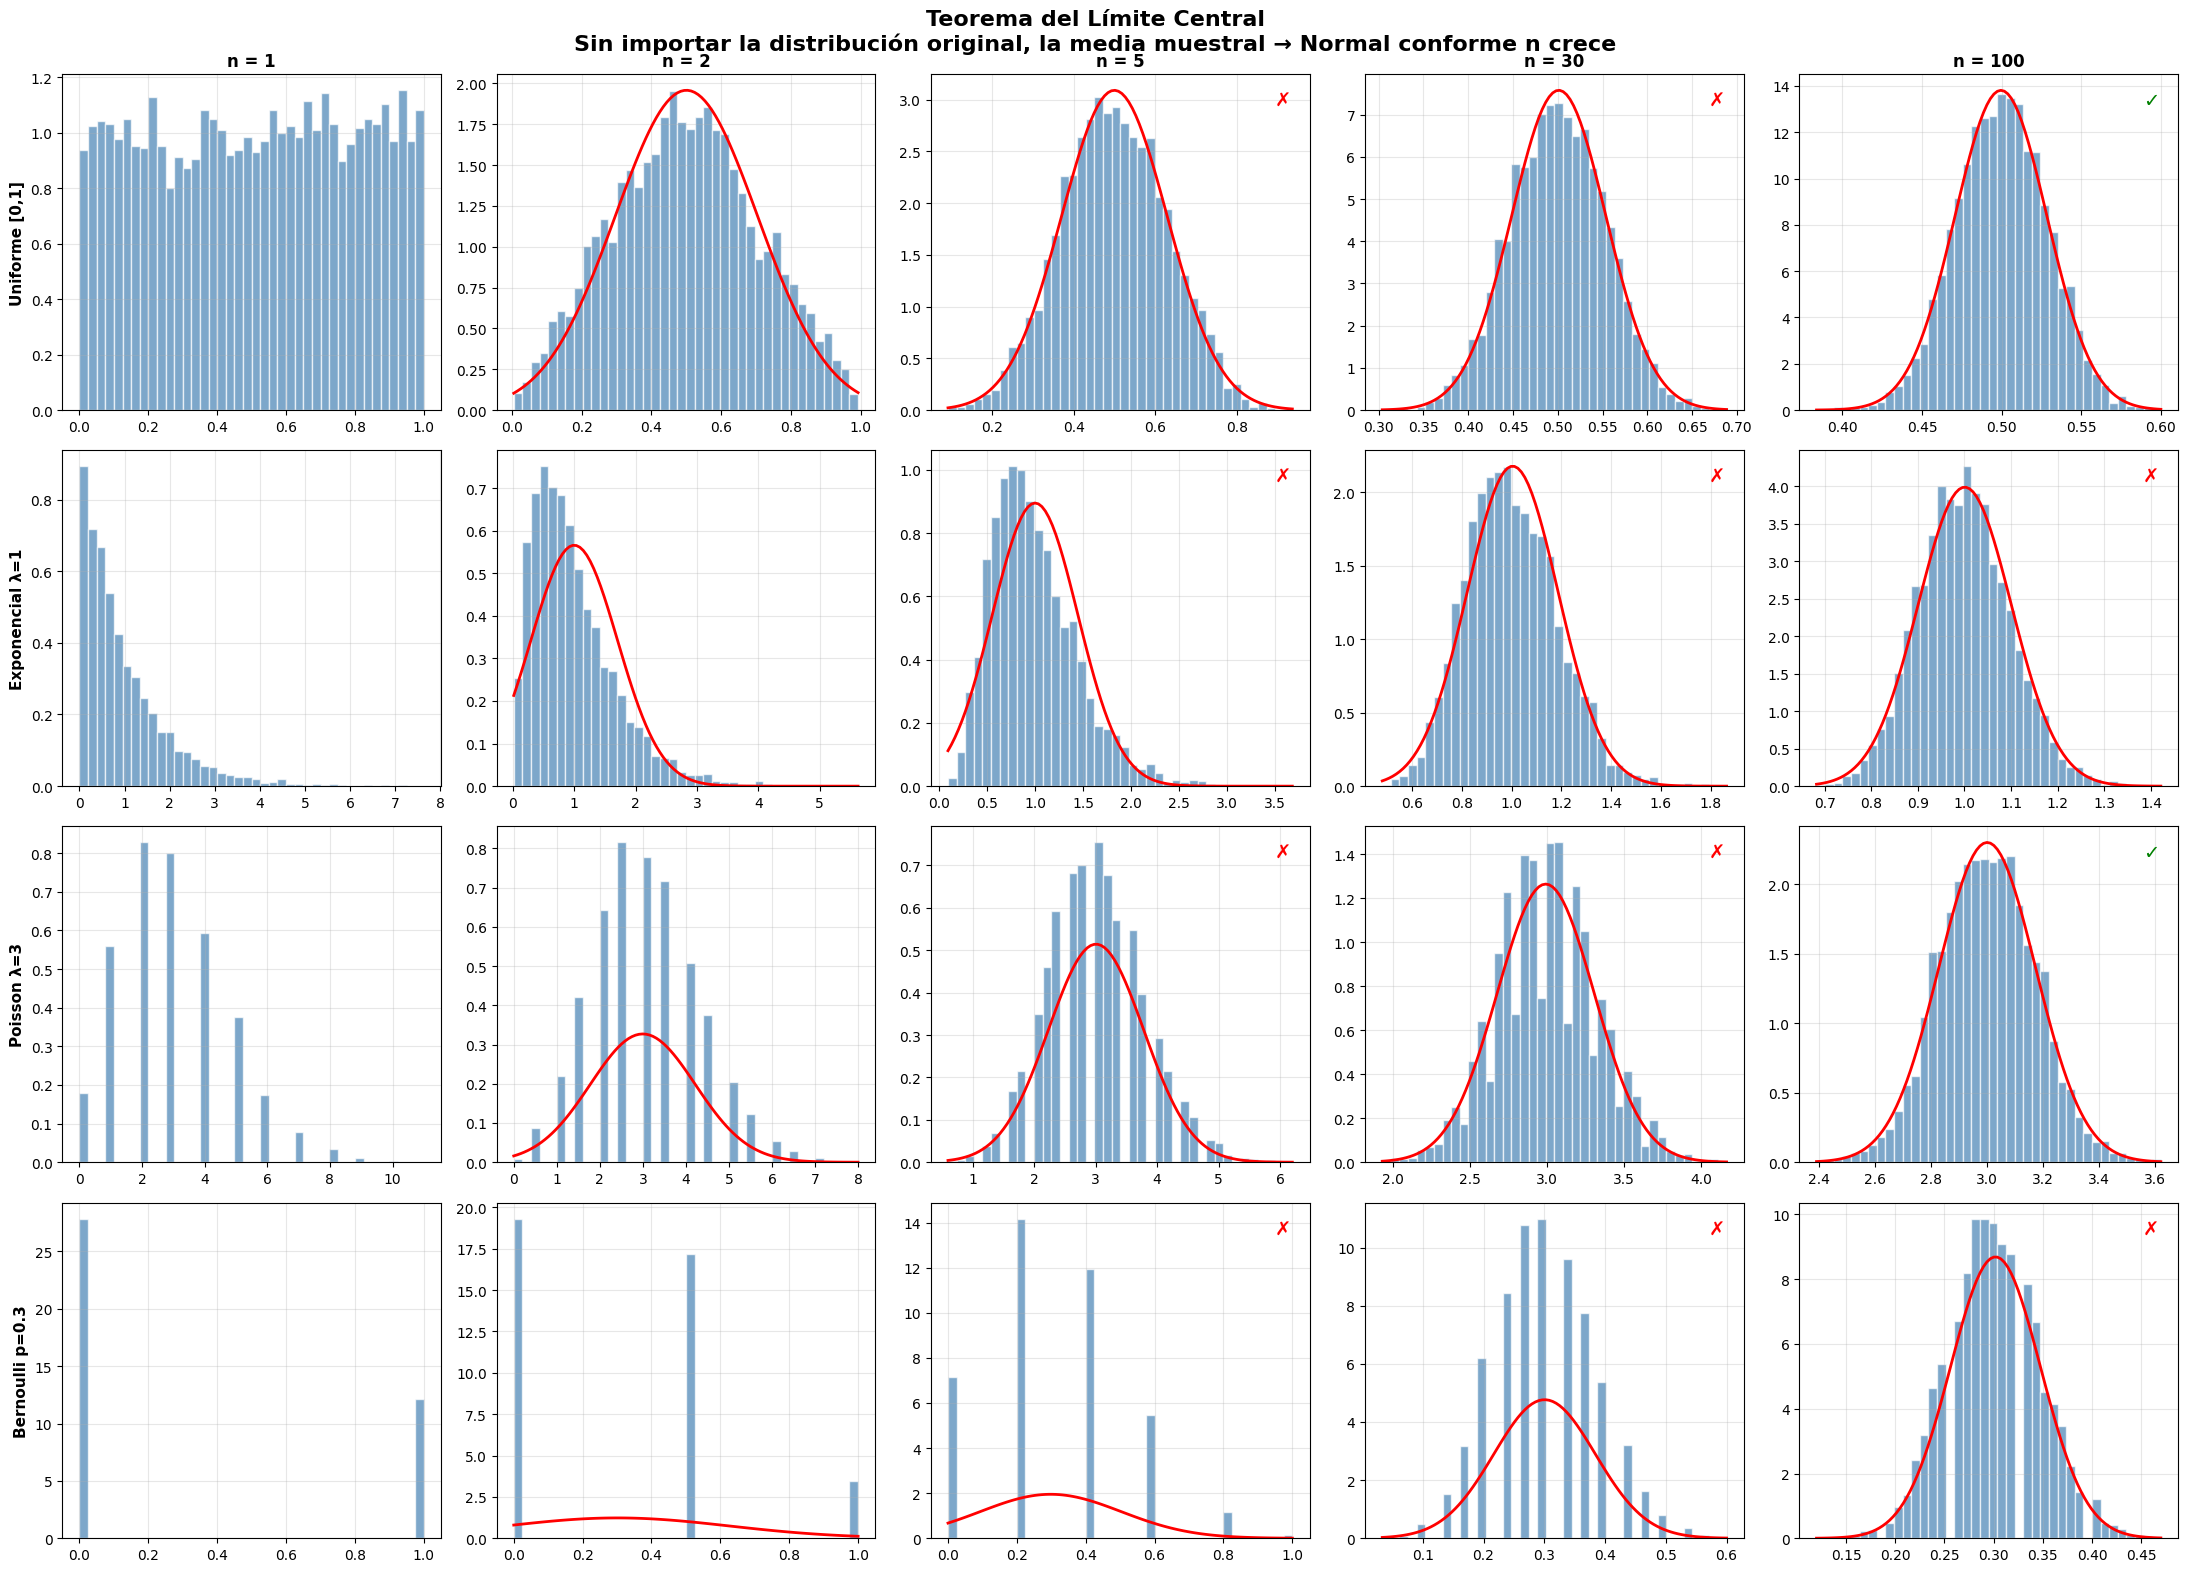

🎯 El TLC en acción:
   - n=1: la distribución de medias = la distribución original
   - n=2: ya empieza a suavizarse
   - n=5: se ve más simétrica
   - n=30: prácticamente Normal (✓)
   - n=100: completamente Normal

   ¡Funciona con uniforme, exponencial, Poisson, Bernoulli... CUALQUIERA!


In [11]:
# =============================================================================
# TEOREMA DEL LÍMITE CENTRAL — Demostración espectacular
# =============================================================================

fig, axes = plt.subplots(4, 5, figsize=(22, 16))

# Distribuciones originales (muy NO normales)
distribuciones = {
    'Uniforme [0,1]': lambda size: np.random.uniform(0, 1, size),
    'Exponencial λ=1': lambda size: np.random.exponential(1, size),
    'Poisson λ=3': lambda size: np.random.poisson(3, size),
    'Bernoulli p=0.3': lambda size: np.random.binomial(1, 0.3, size),
}

n_samples_list = [1, 2, 5, 30, 100]
n_simulations = 5000

for row, (nombre, generador) in enumerate(distribuciones.items()):
    for col, n_samples in enumerate(n_samples_list):
        # Generar n_simulations medias muestrales de tamaño n_samples
        medias = np.array([generador(n_samples).mean() for _ in range(n_simulations)])

        ax = axes[row, col]
        ax.hist(medias, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='white')

        # Superponer curva normal teórica
        if n_samples > 1:
            # Calcular μ y σ teóricos de la media muestral
            data_full = generador(100000)
            mu_teorico = data_full.mean()
            sigma_teorico = data_full.std() / np.sqrt(n_samples)
            x = np.linspace(medias.min(), medias.max(), 100)
            ax.plot(x, stats.norm.pdf(x, mu_teorico, sigma_teorico),
                   'r-', linewidth=2, label='Normal teórica')

        if row == 0:
            ax.set_title(f'n = {n_samples}', fontsize=12, fontweight='bold')
        if col == 0:
            ax.set_ylabel(nombre, fontsize=11, fontweight='bold')

        # Test de normalidad
        if n_samples >= 5:
            _, p_value = stats.normaltest(medias)
            normal_text = "✓" if p_value > 0.05 else "✗"
            ax.text(0.95, 0.95, f'{normal_text}', transform=ax.transAxes,
                   fontsize=14, va='top', ha='right',
                   color='green' if p_value > 0.05 else 'red')

plt.suptitle('Teorema del Límite Central\n'
             'Sin importar la distribución original, la media muestral → Normal conforme n crece',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("🎯 El TLC en acción:")
print("   - n=1: la distribución de medias = la distribución original")
print("   - n=2: ya empieza a suavizarse")
print("   - n=5: se ve más simétrica")
print("   - n=30: prácticamente Normal (✓)")
print("   - n=100: completamente Normal")
print("\n   ¡Funciona con uniforme, exponencial, Poisson, Bernoulli... CUALQUIERA!")

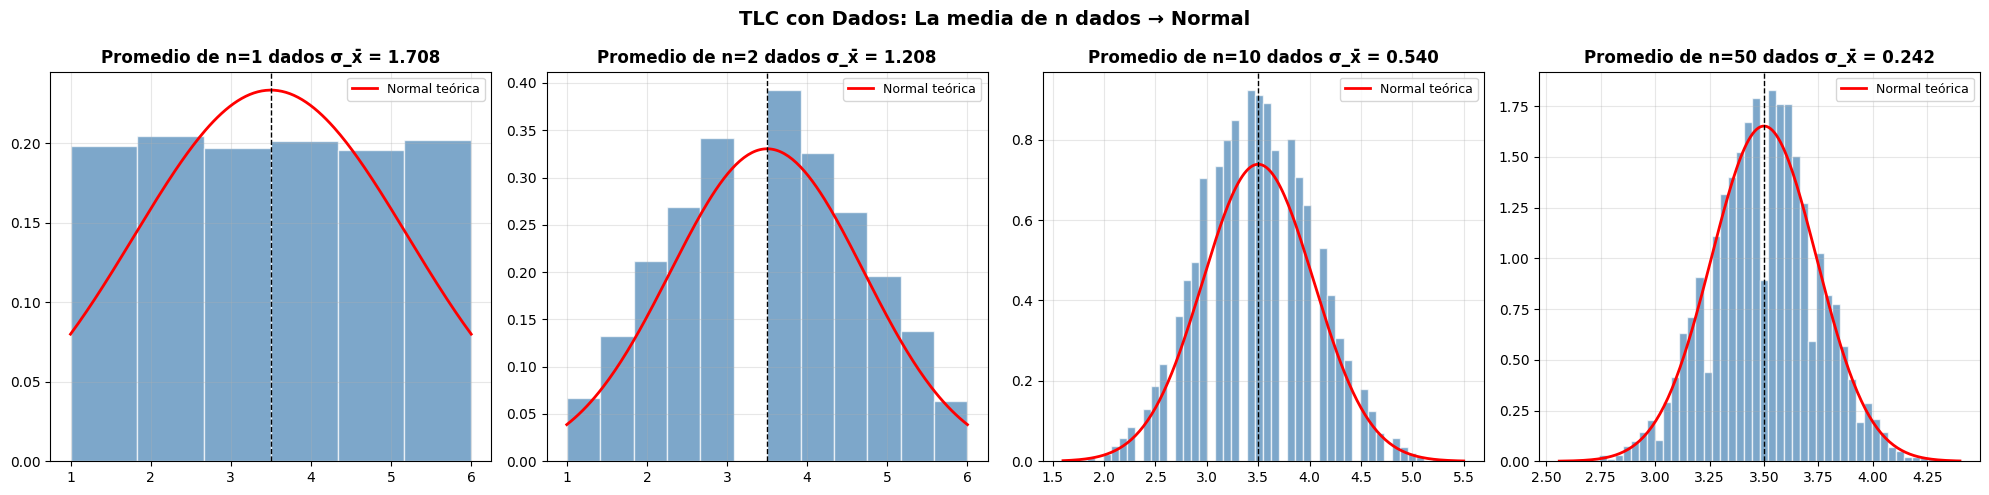

💡 A medida que n crece:
   - La distribución de medias se estrecha (σ/√n)
   - Se vuelve más simétrica
   - Se acerca a una Normal perfecta


In [12]:
# --- Demostración interactiva del TLC con un dado ---
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

n_sims = 10000
ns = [1, 2, 10, 50]

for i, n in enumerate(ns):
    medias = [np.random.randint(1, 7, n).mean() for _ in range(n_sims)]

    axes[i].hist(medias, bins=min(50, 6*n), density=True, alpha=0.7,
                color='steelblue', edgecolor='white')

    mu = 3.5
    sigma = np.sqrt(35/12) / np.sqrt(n)  # Var(dado) = 35/12
    x = np.linspace(min(medias), max(medias), 200)
    axes[i].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label='Normal teórica')

    axes[i].set_title(f'Promedio de n={n} dados σ_x̄ = {sigma:.3f}',
                     fontsize=12, fontweight='bold')
    axes[i].axvline(3.5, color='black', linestyle='--', linewidth=1)
    axes[i].legend(fontsize=9)

plt.suptitle('TLC con Dados: La media de n dados → Normal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 A medida que n crece:")
print("   - La distribución de medias se estrecha (σ/√n)")
print("   - Se vuelve más simétrica")
print("   - Se acerca a una Normal perfecta")

## 8. Intervalos de Confianza

### Idea

No basta con dar una estimación puntual ($\bar{x} = 52.3$).
Queremos un **rango** que probablemente contenga el parámetro real.

### Intervalo de confianza al $(1-\alpha)$% para la media:

$$\bar{x} \pm z_{\alpha/2} \cdot \frac{s}{\sqrt{n}}$$

Donde:
- $z_{\alpha/2}$ = valor crítico de la Normal (1.96 para 95%)
- $s$ = desviación estándar muestral
- $n$ = tamaño de la muestra
- $s/\sqrt{n}$ = **error estándar** de la media

### ¿Qué significa "95% de confianza"?

**NO** significa "hay 95% de probabilidad de que μ esté en este intervalo".

Significa: si repitiéramos el muestreo muchas veces, el **95% de los intervalos
construidos contendrían** el verdadero μ.

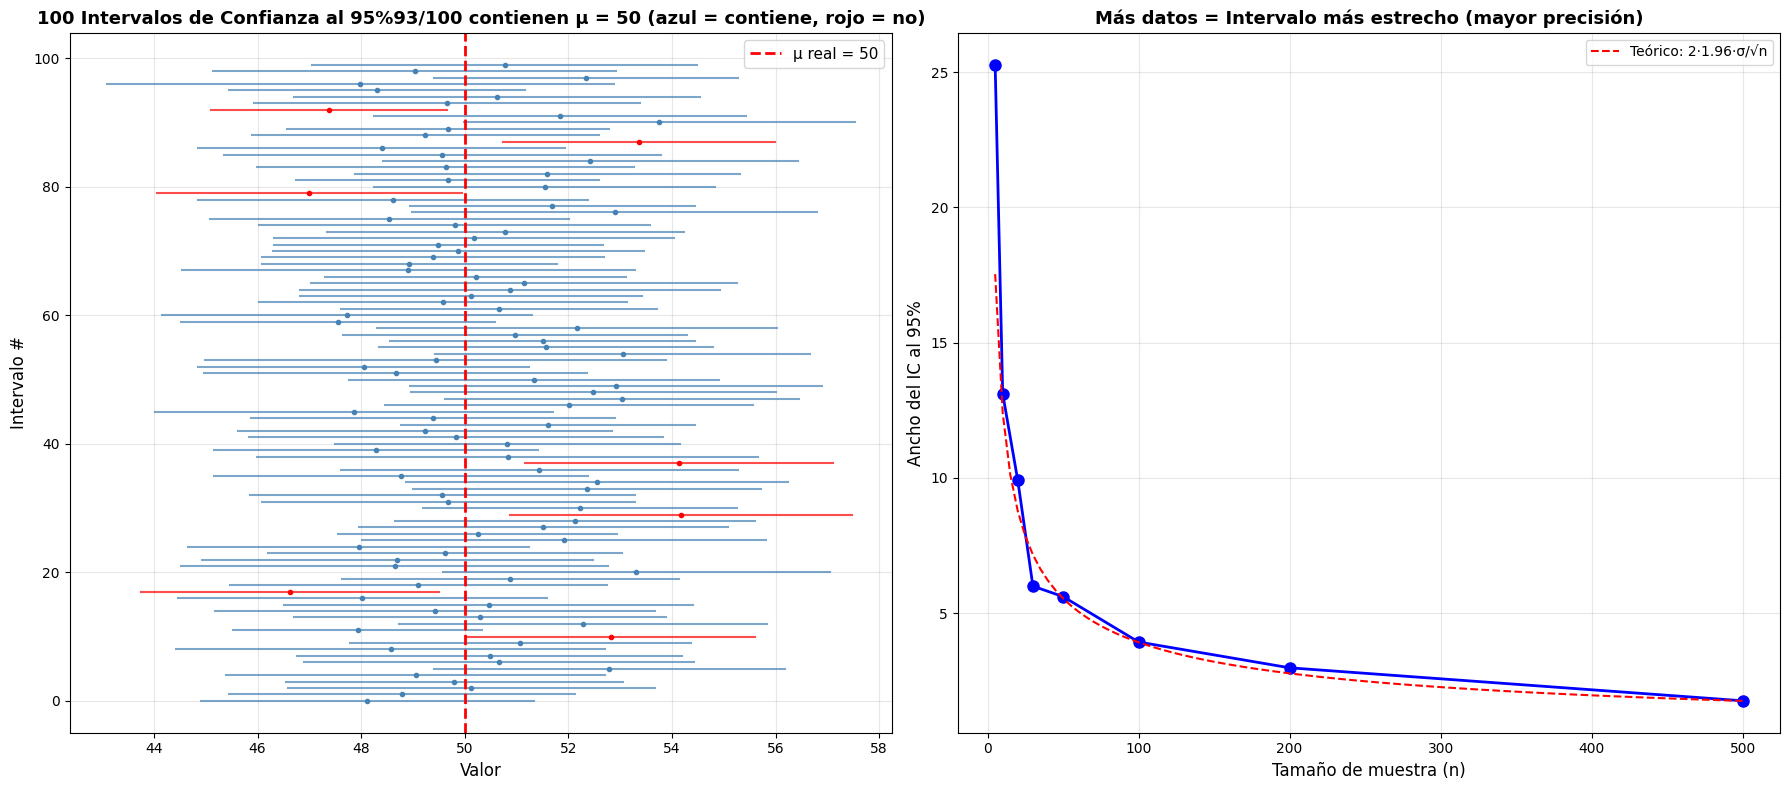

📊 De 100 intervalos al 95%: 93 contienen μ (esperado: ~95)
   Ancho del IC con n=10: 13.11
   Ancho del IC con n=100: 3.93
   Ancho del IC con n=500: 1.76
   → El IC se reduce con 1/√n


In [13]:
# =============================================================================
# INTERVALOS DE CONFIANZA
# =============================================================================

def intervalo_confianza(datos, confianza=0.95):
    """Calcula intervalo de confianza para la media."""
    n = len(datos)
    m = np.mean(datos)
    se = np.std(datos, ddof=1) / np.sqrt(n)
    z = stats.norm.ppf((1 + confianza) / 2)
    return m - z * se, m + z * se

# --- Demostración: 100 intervalos de confianza ---
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

np.random.seed(42)
mu_real = 50  # Media real de la población
sigma_real = 10
n_muestra = 30
n_intervalos = 100
confianza = 0.95

contiene = 0
for i in range(n_intervalos):
    muestra = np.random.normal(mu_real, sigma_real, n_muestra)
    low, high = intervalo_confianza(muestra, confianza)

    color = 'steelblue' if low <= mu_real <= high else 'red'
    if low <= mu_real <= high:
        contiene += 1

    axes[0].plot([low, high], [i, i], color=color, linewidth=1.5, alpha=0.7)
    axes[0].plot(np.mean(muestra), i, 'o', color=color, markersize=3)

axes[0].axvline(mu_real, color='red', linewidth=2, linestyle='--', label=f'μ real = {mu_real}')
axes[0].set_xlabel('Valor', fontsize=12)
axes[0].set_ylabel('Intervalo #', fontsize=12)
axes[0].set_title(f'100 Intervalos de Confianza al 95%'
                  f'{contiene}/100 contienen μ = {mu_real} (azul = contiene, rojo = no)',
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)

# Efecto del tamaño de muestra en el ancho del IC
tamanios = [5, 10, 20, 30, 50, 100, 200, 500]
anchos = []
for n in tamanios:
    muestra = np.random.normal(mu_real, sigma_real, n)
    low, high = intervalo_confianza(muestra)
    anchos.append(high - low)

axes[1].plot(tamanios, anchos, 'bo-', linewidth=2, markersize=8)
axes[1].set_xlabel('Tamaño de muestra (n)', fontsize=12)
axes[1].set_ylabel('Ancho del IC al 95%', fontsize=12)
axes[1].set_title('Más datos = Intervalo más estrecho (mayor precisión)',
                  fontsize=13, fontweight='bold')

# Curva teórica
n_cont = np.linspace(5, 500, 100)
ancho_teorico = 2 * 1.96 * sigma_real / np.sqrt(n_cont)
axes[1].plot(n_cont, ancho_teorico, 'r--', linewidth=1.5, label='Teórico: 2·1.96·σ/√n')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

print(f"📊 De 100 intervalos al 95%: {contiene} contienen μ (esperado: ~95)")
print(f"   Ancho del IC con n=10: {anchos[1]:.2f}")
print(f"   Ancho del IC con n=100: {anchos[5]:.2f}")
print(f"   Ancho del IC con n=500: {anchos[7]:.2f}")
print(f"   → El IC se reduce con 1/√n")

## 9. Pruebas de Hipótesis (Conceptos Clave)

### Estructura de una prueba

1. **H₀** (hipótesis nula): "No hay efecto / diferencia"
2. **H₁** (hipótesis alternativa): "Hay efecto / diferencia"
3. **Estadístico de prueba**: Resumen de los datos
4. **p-valor**: Probabilidad de observar datos tan extremos como los nuestros, **si H₀ fuera cierta**
5. **Decisión**: Si p-valor < α (ej: 0.05) → Rechazar H₀

### Errores

| | H₀ es verdadera | H₀ es falsa |
|---|---|---|
| **No rechazar H₀** | ✅ Correcto | ❌ Error Tipo II (β) |
| **Rechazar H₀** | ❌ Error Tipo I (α) | ✅ Correcto (Poder) |

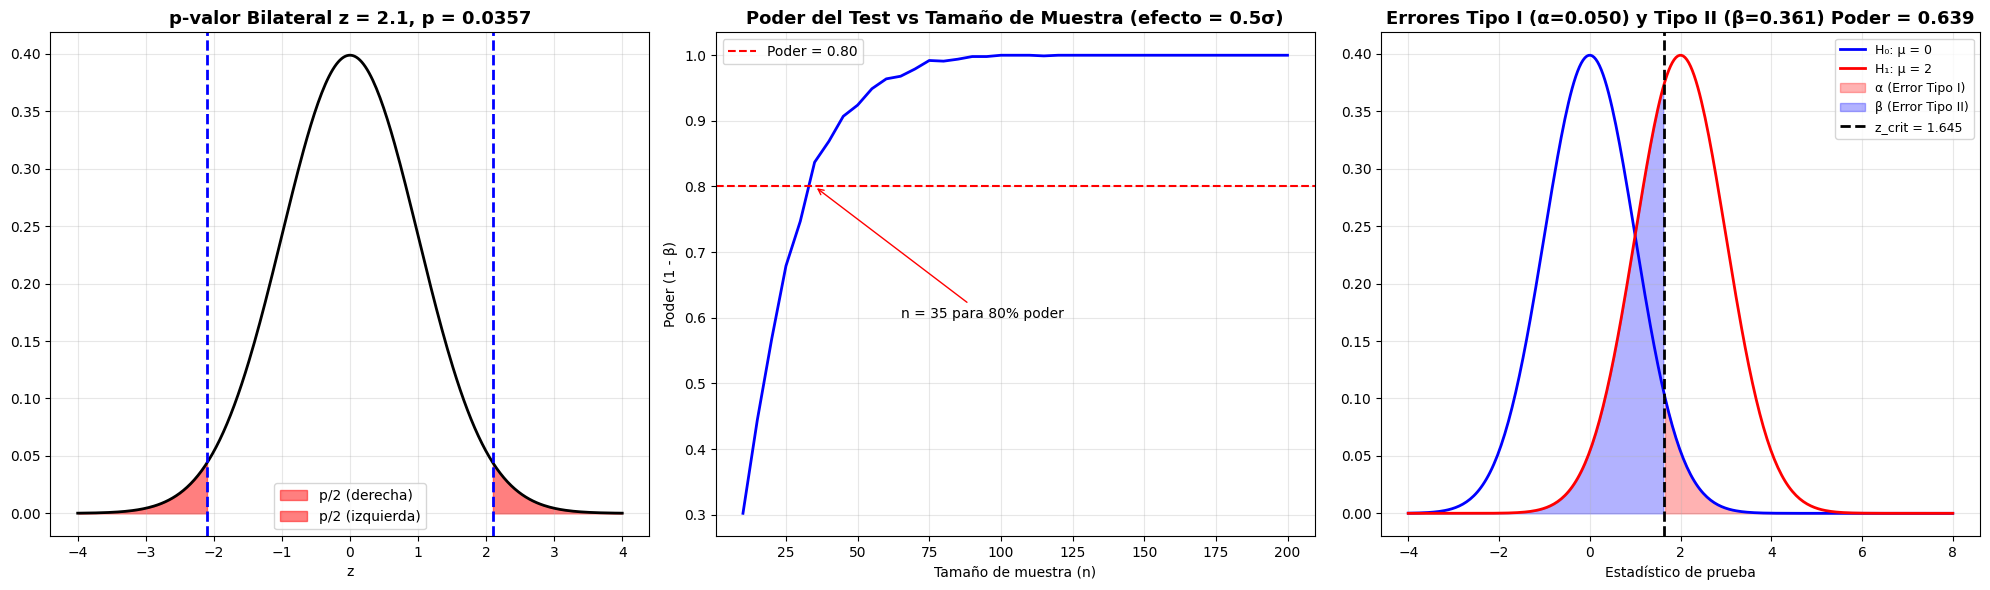

In [14]:
# =============================================================================
# PRUEBAS DE HIPÓTESIS — Demostración visual
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. p-valor: visualización
x = np.linspace(-4, 4, 300)
y = stats.norm.pdf(x)

# Test: ¿la media es diferente de 0? Observamos z = 2.1
z_obs = 2.1

axes[0].plot(x, y, 'k-', linewidth=2)
axes[0].fill_between(x, y, where=(x >= z_obs), alpha=0.5, color='red', label=f'p/2 (derecha)')
axes[0].fill_between(x, y, where=(x <= -z_obs), alpha=0.5, color='red', label=f'p/2 (izquierda)')
axes[0].axvline(z_obs, color='blue', linewidth=2, linestyle='--')
axes[0].axvline(-z_obs, color='blue', linewidth=2, linestyle='--')

p_val = 2 * (1 - stats.norm.cdf(z_obs))
axes[0].set_title(f'p-valor Bilateral z = {z_obs}, p = {p_val:.4f}', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].set_xlabel('z')

# 2. Efecto del tamaño de muestra en el poder
np.random.seed(42)
effect_size = 0.5  # Diferencia real = 0.5σ
n_range = np.arange(10, 201, 5)
powers = []

for n in n_range:
    # Simular 1000 experimentos
    rechazos = 0
    for _ in range(1000):
        muestra = np.random.normal(effect_size, 1, n)  # μ real = 0.5
        _, p = stats.ttest_1samp(muestra, 0)  # H₀: μ = 0
        if p < 0.05:
            rechazos += 1
    powers.append(rechazos / 1000)

axes[1].plot(n_range, powers, 'b-', linewidth=2)
axes[1].axhline(0.8, color='red', linestyle='--', label='Poder = 0.80')
axes[1].set_xlabel('Tamaño de muestra (n)')
axes[1].set_ylabel('Poder (1 - β)')
axes[1].set_title(f'Poder del Test vs Tamaño de Muestra (efecto = {effect_size}σ)',
                  fontsize=13, fontweight='bold')
axes[1].legend()
n_80 = n_range[np.searchsorted(powers, 0.8)]
axes[1].annotate(f'n = {n_80} para 80% poder', (n_80, 0.8), fontsize=10,
                arrowprops=dict(arrowstyle='->', color='red'), xytext=(n_80+30, 0.6))

# 3. Errores Tipo I y Tipo II
x = np.linspace(-4, 8, 300)
y_h0 = stats.norm.pdf(x, 0, 1)  # H₀: μ = 0
y_h1 = stats.norm.pdf(x, 2, 1)  # H₁: μ = 2

z_crit = 1.645  # α = 0.05, unilateral

axes[2].plot(x, y_h0, 'b-', linewidth=2, label='H₀: μ = 0')
axes[2].plot(x, y_h1, 'r-', linewidth=2, label='H₁: μ = 2')
axes[2].fill_between(x, y_h0, where=(x >= z_crit), alpha=0.3, color='red', label='α (Error Tipo I)')
axes[2].fill_between(x, y_h1, where=(x <= z_crit), alpha=0.3, color='blue', label='β (Error Tipo II)')
axes[2].axvline(z_crit, color='black', linewidth=2, linestyle='--', label=f'z_crit = {z_crit}')

alpha = 1 - stats.norm.cdf(z_crit)
beta = stats.norm.cdf(z_crit, 2, 1)
axes[2].set_title(f'Errores Tipo I (α={alpha:.3f}) y Tipo II (β={beta:.3f}) Poder = {1-beta:.3f}',
                  fontsize=13, fontweight='bold')
axes[2].legend(fontsize=9, loc='upper right')
axes[2].set_xlabel('Estadístico de prueba')

plt.tight_layout()
plt.show()

## 10. Bootstrap: Remuestreo para Estimar Cualquier Cosa

### Idea

No necesitas fórmulas analíticas para intervalos de confianza.
Puedes **remuestrear** tus datos con reemplazo y estimar la distribución de cualquier estadístico.

### Algoritmo

1. De tus $n$ datos, toma una muestra de tamaño $n$ **con reemplazo**
2. Calcula el estadístico de interés (media, mediana, correlación, lo que sea)
3. Repite B veces (ej: B = 10,000)
4. Los percentiles 2.5% y 97.5% de las B estimaciones = IC al 95%

### Ventajas
- Funciona para **cualquier estadístico** (no solo la media)
- No asume distribución paramétrica
- Simple de implementar

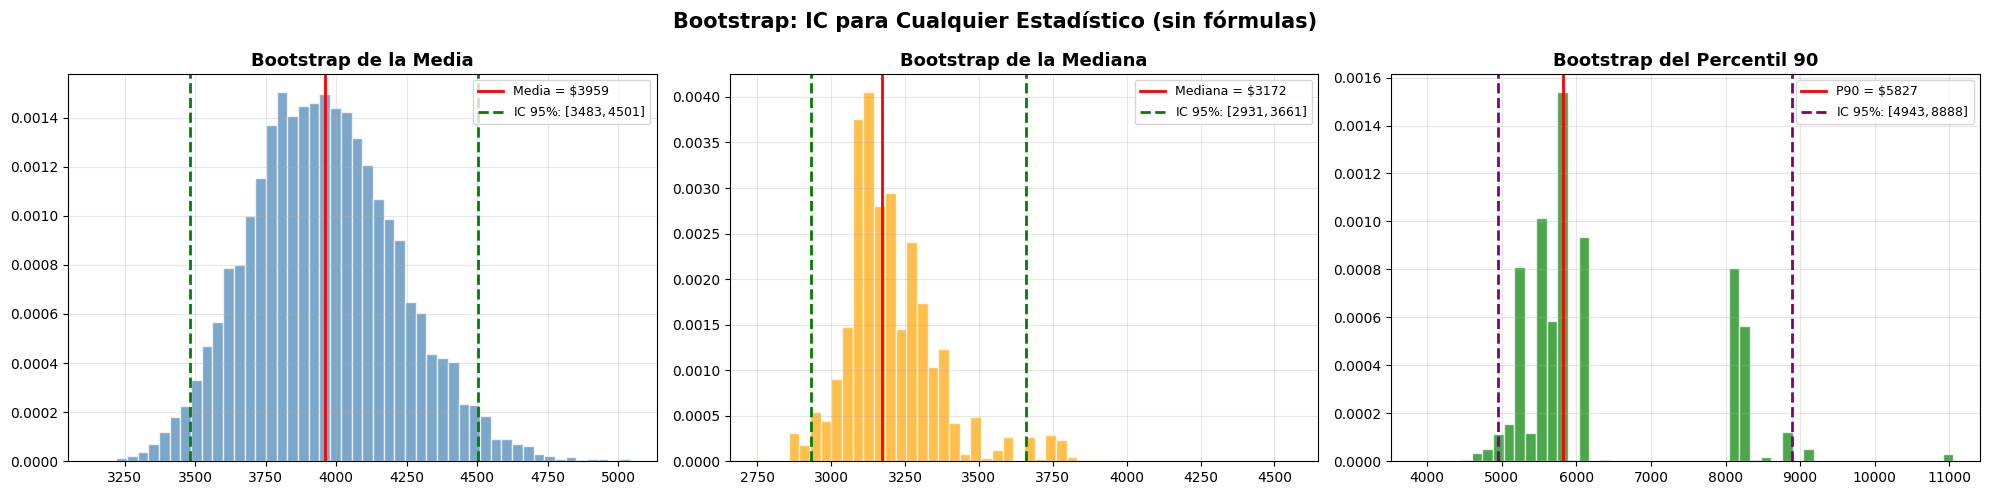

💡 Bootstrap permite IC para estadísticos donde NO hay fórmula:
   Media:      $3959 IC95%=[$3483, $4501]
   Mediana:    $3172 IC95%=[$2931, $3661]
   Percentil90: $5827 IC95%=[$4943, $8888]


In [15]:
# =============================================================================
# BOOTSTRAP
# =============================================================================

def bootstrap(datos, estadistico, n_boot=10000, confianza=0.95):
    """
    Bootstrap: estima IC para cualquier estadístico.

    Args:
        datos: array de datos
        estadistico: función que calcula el estadístico (ej: np.mean, np.median)
        n_boot: número de re-muestras
        confianza: nivel de confianza
    """
    n = len(datos)
    estimaciones = np.zeros(n_boot)

    for i in range(n_boot):
        muestra = np.random.choice(datos, size=n, replace=True)
        estimaciones[i] = estadistico(muestra)

    alpha = (1 - confianza) / 2
    ic_low = np.percentile(estimaciones, alpha * 100)
    ic_high = np.percentile(estimaciones, (1 - alpha) * 100)

    return estimaciones, ic_low, ic_high

# --- Demostración ---
np.random.seed(42)
datos_salarios = np.concatenate([
    np.random.normal(3000, 500, 40),
    np.random.normal(5000, 800, 15),
    np.random.exponential(2000, 5) + 8000
])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Bootstrap de la MEDIA
boot_media, low_m, high_m = bootstrap(datos_salarios, np.mean)
axes[0].hist(boot_media, bins=50, color='steelblue', alpha=0.7, density=True, edgecolor='white')
axes[0].axvline(np.mean(datos_salarios), color='red', linewidth=2, label=f'Media = ${np.mean(datos_salarios):.0f}')
axes[0].axvline(low_m, color='green', linewidth=2, linestyle='--', label=f'IC 95%: [${low_m:.0f}, ${high_m:.0f}]')
axes[0].axvline(high_m, color='green', linewidth=2, linestyle='--')
axes[0].set_title('Bootstrap de la Media', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)

# 2. Bootstrap de la MEDIANA
boot_mediana, low_md, high_md = bootstrap(datos_salarios, np.median)
axes[1].hist(boot_mediana, bins=50, color='orange', alpha=0.7, density=True, edgecolor='white')
axes[1].axvline(np.median(datos_salarios), color='red', linewidth=2, label=f'Mediana = ${np.median(datos_salarios):.0f}')
axes[1].axvline(low_md, color='green', linewidth=2, linestyle='--', label=f'IC 95%: [${low_md:.0f}, ${high_md:.0f}]')
axes[1].axvline(high_md, color='green', linewidth=2, linestyle='--')
axes[1].set_title('Bootstrap de la Mediana', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)

# 3. Bootstrap del PERCENTIL 90 (¡difícil analíticamente!)
boot_p90, low_p90, high_p90 = bootstrap(datos_salarios, lambda x: np.percentile(x, 90))
axes[2].hist(boot_p90, bins=50, color='green', alpha=0.7, density=True, edgecolor='white')
p90_real = np.percentile(datos_salarios, 90)
axes[2].axvline(p90_real, color='red', linewidth=2, label=f'P90 = ${p90_real:.0f}')
axes[2].axvline(low_p90, color='purple', linewidth=2, linestyle='--', label=f'IC 95%: [${low_p90:.0f}, ${high_p90:.0f}]')
axes[2].axvline(high_p90, color='purple', linewidth=2, linestyle='--')
axes[2].set_title('Bootstrap del Percentil 90', fontsize=13, fontweight='bold')
axes[2].legend(fontsize=9)

plt.suptitle('Bootstrap: IC para Cualquier Estadístico (sin fórmulas)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Bootstrap permite IC para estadísticos donde NO hay fórmula:")
print(f"   Media:      ${np.mean(datos_salarios):.0f} IC95%=[${low_m:.0f}, ${high_m:.0f}]")
print(f"   Mediana:    ${np.median(datos_salarios):.0f} IC95%=[${low_md:.0f}, ${high_md:.0f}]")
print(f"   Percentil90: ${p90_real:.0f} IC95%=[${low_p90:.0f}, ${high_p90:.0f}]")

## 11. Paradoja de Simpson: Cuando los Datos Mienten

### Una tendencia puede **revertirse** al agregar o desagregar datos

Ejemplo clásico: El Tratamiento A parece mejor en general,
pero al separar por grupo, el Tratamiento B es mejor en CADA grupo.

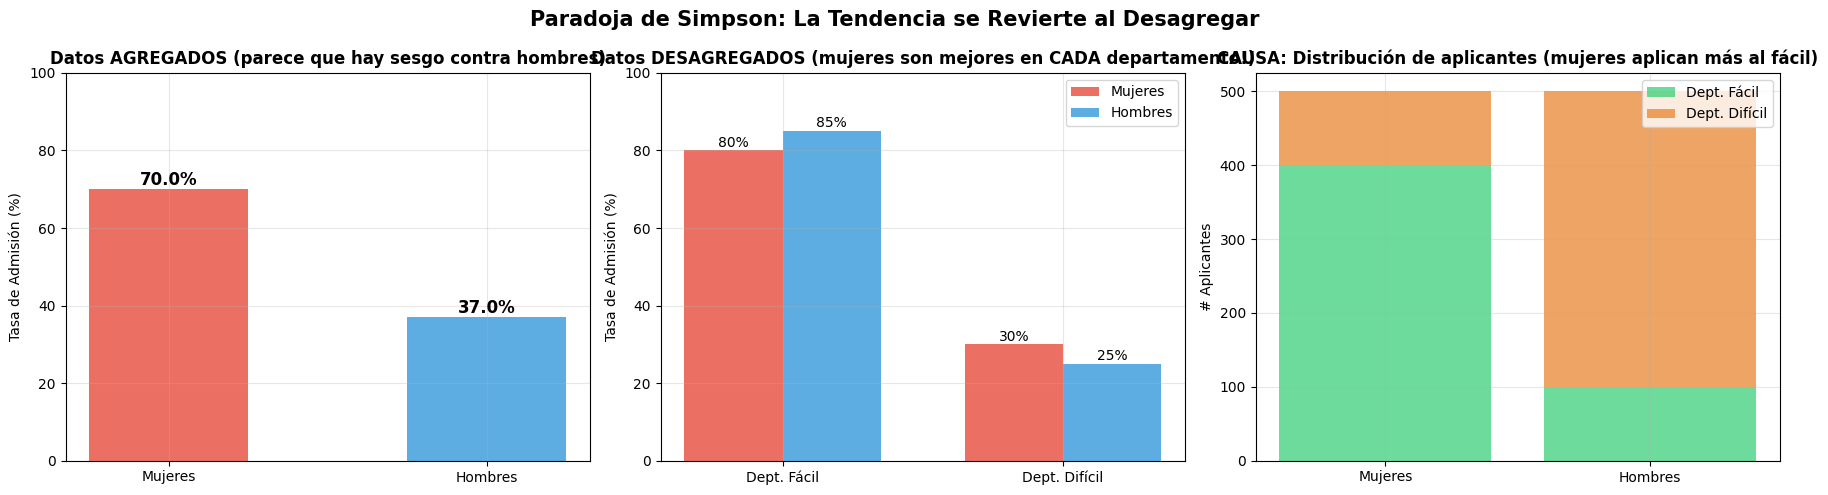

⚠️ Paradoja de Simpson:
   AGREGADO: Mujeres 70.0% vs Hombres 37.0%  ← Mujeres 'ganan'
   FÁCIL:    Mujeres 80% vs Hombres 85%  ← ¡Hombres mejor!
   DIFÍCIL:  Mujeres 30% vs Hombres 25%  ← ¡Hombres mejor!

   CAUSA: Las mujeres aplican más al departamento fácil (80% vs 20%)
   Los hombres aplican más al difícil → su tasa total baja artificialmente


In [16]:
# =============================================================================
# PARADOJA DE SIMPSON
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Datos simulados: admisión universitaria
np.random.seed(42)

# Departamento fácil: muchas mujeres aplican
n_mujeres_facil = 400
n_hombres_facil = 100
admit_mujeres_facil = int(0.80 * n_mujeres_facil)  # 80% admitidas
admit_hombres_facil = int(0.85 * n_hombres_facil)   # 85% admitidos

# Departamento difícil: muchos hombres aplican
n_mujeres_dificil = 100
n_hombres_dificil = 400
admit_mujeres_dificil = int(0.30 * n_mujeres_dificil)  # 30% admitidas
admit_hombres_dificil = int(0.25 * n_hombres_dificil)   # 25% admitidos

# Totales
total_mujeres = n_mujeres_facil + n_mujeres_dificil
total_hombres = n_hombres_facil + n_hombres_dificil
admit_mujeres = admit_mujeres_facil + admit_mujeres_dificil
admit_hombres = admit_hombres_facil + admit_hombres_dificil

tasa_mujeres = admit_mujeres / total_mujeres * 100
tasa_hombres = admit_hombres / total_hombres * 100

# 1. Datos agregados (¡engañoso!)
labels = ['Mujeres', 'Hombres']
tasas_total = [tasa_mujeres, tasa_hombres]
colors = ['#E74C3C', '#3498DB']
bars = axes[0].bar(labels, tasas_total, color=colors, alpha=0.8, width=0.5)
axes[0].set_ylabel('Tasa de Admisión (%)')
axes[0].set_title('Datos AGREGADOS (parece que hay sesgo contra hombres)', fontsize=12, fontweight='bold')
for bar, val in zip(bars, tasas_total):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 100)

# 2. Por departamento (¡realidad!)
x = np.arange(2)
w = 0.35

tasa_m_facil = admit_mujeres_facil / n_mujeres_facil * 100
tasa_h_facil = admit_hombres_facil / n_hombres_facil * 100
tasa_m_dificil = admit_mujeres_dificil / n_mujeres_dificil * 100
tasa_h_dificil = admit_hombres_dificil / n_hombres_dificil * 100

b1 = axes[1].bar(x - w/2, [tasa_m_facil, tasa_m_dificil], w, label='Mujeres', color='#E74C3C', alpha=0.8)
b2 = axes[1].bar(x + w/2, [tasa_h_facil, tasa_h_dificil], w, label='Hombres', color='#3498DB', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Dept. Fácil', 'Dept. Difícil'])
axes[1].set_ylabel('Tasa de Admisión (%)')
axes[1].set_title('Datos DESAGREGADOS (mujeres son mejores en CADA departamento!)',
                  fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].set_ylim(0, 100)

for b in [b1, b2]:
    for bar in b:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    f'{bar.get_height():.0f}%', ha='center', fontsize=10)

# 3. Explicación: composición de los aplicantes
datos_comp = [[n_mujeres_facil, n_mujeres_dificil], [n_hombres_facil, n_hombres_dificil]]
axes[2].bar(['Mujeres', 'Hombres'], [n_mujeres_facil, n_hombres_facil],
           label='Dept. Fácil', color='#2ECC71', alpha=0.7)
axes[2].bar(['Mujeres', 'Hombres'], [n_mujeres_dificil, n_hombres_dificil],
           bottom=[n_mujeres_facil, n_hombres_facil],
           label='Dept. Difícil', color='#E67E22', alpha=0.7)
axes[2].set_ylabel('# Aplicantes')
axes[2].set_title('CAUSA: Distribución de aplicantes (mujeres aplican más al fácil)',
                  fontsize=12, fontweight='bold')
axes[2].legend()

plt.suptitle('Paradoja de Simpson: La Tendencia se Revierte al Desagregar',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("⚠️ Paradoja de Simpson:")
print(f"   AGREGADO: Mujeres {tasa_mujeres:.1f}% vs Hombres {tasa_hombres:.1f}%  ← Mujeres 'ganan'")
print(f"   FÁCIL:    Mujeres {tasa_m_facil:.0f}% vs Hombres {tasa_h_facil:.0f}%  ← ¡Hombres mejor!")
print(f"   DIFÍCIL:  Mujeres {tasa_m_dificil:.0f}% vs Hombres {tasa_h_dificil:.0f}%  ← ¡Hombres mejor!")
print(f"\n   CAUSA: Las mujeres aplican más al departamento fácil (80% vs 20%)")
print(f"   Los hombres aplican más al difícil → su tasa total baja artificialmente")

## 12. Resumen: Mapa de Conceptos Estadísticos

### Todos los conceptos cubiertos:

| Categoría | Concepto | Fórmula clave |
|-----------|---------|--------------|
| **Tendencia Central** | Media | $\bar{x} = \frac{1}{n}\sum x_i$ |
| | Mediana | Valor central de datos ordenados |
| | Moda | Valor más frecuente |
| **Dispersión** | Varianza | $s^2 = \frac{1}{n-1}\sum(x_i - \bar{x})^2$ |
| | Desv. Estándar | $s = \sqrt{s^2}$ |
| | IQR | $Q_3 - Q_1$ |
| | CV | $\sigma / \bar{x} \times 100\%$ |
| **Forma** | Asimetría | $\gamma_1 = \mu_3 / \sigma^3$ |
| | Curtosis | $\gamma_2 = \mu_4 / \sigma^4 - 3$ |
| **Relaciones** | Covarianza | $\text{Cov}(X,Y) = \frac{1}{n-1}\sum(x_i-\bar{x})(y_i-\bar{y})$ |
| | Correlación | $r = \text{Cov}(X,Y) / (\sigma_X \sigma_Y)$ |
| **Teoremas** | Ley Grandes Números | $\bar{X}_n \to \mu$ cuando $n \to \infty$ |
| | Límite Central | $\bar{X}_n \sim N(\mu, \sigma^2/n)$ |
| **Inferencia** | IC | $\bar{x} \pm z_{\alpha/2} \cdot s/\sqrt{n}$ |
| | Pruebas de hipótesis | p-valor < α → rechazar H₀ |
| | Bootstrap | Remuestreo con reemplazo |

### :

```
Estadística Descriptiva           Estadística Inferencial
(describir datos)                 (generalizar a población)
        │                                  │
        ├── EDA (Exploratory Data          ├── Train/Test Split (muestreo)
        │   Analysis)                      ├── Cross-Validation (IC del score)
        ├── Feature Engineering            ├── Regularización (sesgo-varianza)
        │   (normalización con μ,σ)        ├── Pruebas A/B (hipótesis)
        └── Detección de outliers          └── Bayesian ML (probabilidad)
            (IQR, z-scores)
```

---